# 37. KAIST vs NewCollege: sensor and odometry domain-shift audit

**Purpose:** determine *what is measurably different* between the KAIST data used to train the calibration networks (one IMU, two LiDARs) and NewCollege (two IMUs, one LiDAR). No training and no calibration updates in the main analysis.

The main scientific hypothesis is that **KAIST LiDAR relative poses were derived from scan-to-map registrations while NewCollege relative poses were derived from scan-to-scan registrations**. This notebook measures different motion, sampling, short-timescale roughness, IMU–LiDAR consistency and network-input distributions. **None of these alone proves the registration algorithm caused the difference**: the platform, trajectories, LiDAR model, IMUs and environment all change too.

Sections: provenance/preflight → physically comparable 5 s windows → signal statistics → time-dependent plots → block-aware distribution comparisons → LiDAR roughness → IMU–LiDAR rotation & clock-offset sweep → canonicalized network-token shift → optional frozen-checkpoint correction-direction probe → diagnostic report.

**Sensor-frame rule:** all sensors are represented by their native modalities. The supplied nominal extrinsics are used *only* in geometry/physical consistency and the optional controlled NN diagnostic. This notebook does **not** invent a second LiDAR from Ouster gyroscope data. Nominal time shifts are uncertain in NewCollege, so sweep both signs and state the convention explicitly.

## 1. Paths, experiment scope and execution switches

Default KAIST sequences match notebook 32's **held-out Urban38/Urban39**. Optionally set `KAIST_SEQUENCES` to training sequences to compare train-domain statistics separately. Use the 5-second non-overlapping windows of notebooks 32/36. The execution modes can be switched off independently to obtain a quick initial report.

In [39]:
from pathlib import Path
import torch  # Required here because DEVICE is constructed in this cell

KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
KAIST_LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
KAIST_SEQUENCES = ('Urban38', 'Urban39')
KAIST_RIGHT_LIDAR_POSE_FILENAME = 'lidar_map_poses_vlp_right.csv'
NEWCOLLEGE_ROOT = Path('/mnt/d/Downloads/MobRobLab/NewCollegeDataset')
NEWCOLLEGE_LIDAR_CSV = NEWCOLLEGE_ROOT / 'lidar_odometry.csv'
REALSENSE_IMU_DIR = NEWCOLLEGE_ROOT / '01_short_experiment/raw_format/realsense_imu'
OUSTER_IMU_DIR = NEWCOLLEGE_ROOT / '01_short_experiment/raw_format/ouster_imu'
CALIBRATION_FOLDER = NEWCOLLEGE_ROOT / '04_calibration'
CALIBRATION_ZIP = NEWCOLLEGE_ROOT / '04_calibration.zip'
OLD_PROJECT_SRC = None  # Set to Path('~/Skoltech/phd_proposal/src').expanduser() if needed

OUT_NAME = '37_kaist_newcollege_domain_shift'
WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
MAX_KAIST_WINDOWS_PER_SEQUENCE = 160  # None for every available window; selected uniformly in time
MAX_NEWCOLLEGE_WINDOWS = None
TARGET_IMU_FREQUENCY_HZ = 100.0
MAX_IMU_FILES = None
REALSENSE_IMU_NAME = None
OUSTER_IMU_NAME = None
MIN_IMU_SAMPLES_PER_WINDOW = 8
MIN_LIDAR_EDGES_PER_WINDOW = 2
MAX_IMU_SAMPLE_GAP_S = 0.5

RANDOM_SEED = 12345
BLOCK_SIZE_WINDOWS = 6  # Approximately 30 s blocks; not individual IMU samples
BOOTSTRAP_REPEATS = 500
SIGNIFICANCE_FDR = 0.05
MAX_HIST_SAMPLES_PER_STREAM = 12000

RUN_PHYSICAL_CONSISTENCY = True
CONSISTENCY_WINDOWS_PER_SEQUENCE = 14
CONSISTENCY_MAX_EDGES_PER_WINDOW = 12
CONSISTENCY_ACTIVE_RATE_RADPS = 0.035
TAU_SWEEP_S = tuple(round(x, 5) for x in __import__('numpy').arange(-0.30, 0.3001, 0.025))
RUN_TOKEN_DIAGNOSTICS = True
TOKEN_WINDOWS_PER_SEQUENCE = 30
RUN_MODEL_PROBE = True  # Enable after physical/statistical diagnostics pass; loads two large checkpoints
MODEL_PROBE_WINDOWS_PER_SEQUENCE = 5
MODEL_PROBE_ANGLES_DEG = (0., 15., 60.)
BASELINE_CHECKPOINT = Path('runs/kaist_pooled_calibration_paired_002.16_correction_only/best.pt')
OBSERVABILITY_CHECKPOINT = Path('runs/kaist_pooled_calibration_paired_002.15_observability_output/joint_best.pt')
DEVICE_NAME = 'cuda'  # Model probe only; use 'cpu' if CUDA is unavailable
MODEL_DTYPE_NAME = 'float32'
SAVE_FIGURES = True
DEVICE = torch.device(DEVICE_NAME)
MODEL_DTYPE = getattr(torch, MODEL_DTYPE_NAME)

## 2. Imports and executable preflight

All dataset interfaces below follow notebooks 32 and 36. Nothing is read from another notebook's in-memory state.

In [40]:
import sys, json, warnings, zipfile, hashlib, dataclasses
from dataclasses import replace
from collections import defaultdict
import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation
from scipy.stats import wasserstein_distance, ks_2samp
from scipy.signal import welch
from IPython.display import display
from tqdm.auto import tqdm

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Open notebook 37 from the nn-obs-calib repository tree (src/obscalib).')
sys.path.insert(0, str(ROOT / 'src'))
if OLD_PROJECT_SRC is not None:
    sys.path.insert(0, str(Path(OLD_PROJECT_SRC).expanduser()))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.config import WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.calibration.state import CalibrationState
from obscalib.geometry.processing import GeometryProcessor
from obscalib.tokenization.tokenizer import Tokenizer

try:
    from new_college_dataset import load_imus
    from new_college_dataset.lidar import load_lidar_data_csv
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError('NewCollege loader not found. Set OLD_PROJECT_SRC to phd_proposal/src in cell 1.') from exc

OUT = ROOT / 'runs' / OUT_NAME
OUT.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
for path in (KAIST_DATASET_ROOT, KAIST_LIDAR_POSE_ROOT, NEWCOLLEGE_LIDAR_CSV, REALSENSE_IMU_DIR, OUSTER_IMU_DIR):
    if not path.exists():
        raise FileNotFoundError(f'Missing dataset resource: {path}')
if not CALIBRATION_FOLDER.is_dir() and not CALIBRATION_ZIP.is_file():
    raise FileNotFoundError('NewCollege 04_calibration folder/zip missing')
print('Repository:', ROOT)
print('KAIST sequences:', KAIST_SEQUENCES)
print('NewCollege:', NEWCOLLEGE_ROOT)
print('Output:', OUT)

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
KAIST sequences: ('Urban38', 'Urban39')
NewCollege: /mnt/d/Downloads/MobRobLab/NewCollegeDataset
Output: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/37_kaist_newcollege_domain_shift


## 3. KAIST: load held-out physical windows

The exact sensor transforms, data loaders, scan-to-map CSV naming and window construction are taken from notebook 32. Right and left LiDAR streams must both be present: failure is explicit, not silently reduced to one LiDAR.

In [41]:
KAIST_KEYS = ('imu', 'lidar', 'lidar_right')
T_B_L = np.array([[-0.514066,-0.702201,-0.492595,-0.440699],[0.486485,-0.711672,0.506809,0.397052],[-0.706447,0.0208933,0.707457,1.90953],[0.,0.,0.,1.]])
T_B_L_right = np.array([[-0.512152,0.699241,-0.498761,-0.449885],[-0.494811,-0.714859,-0.494104,-0.416713],[-0.702041,-0.0062642,0.712109,1.91294],[0.,0.,0.,1.]])
T_I_B = np.eye(4); T_I_B[:3,3] = [-0.07,0.,1.7]
kaist_rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B),T_B_L=T_B_L,tau_imu_s=0.,tau_lidar_s=0.,T_B_L_right=T_B_L_right,tau_lidar_right_s=0.)
window_cfg = WindowingConfig(window_duration_s=WINDOW_DURATION_S,window_stride_s=WINDOW_STRIDE_S,max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
kaist_specs = build_kaist_sequence_specs(sequence_names=list(KAIST_SEQUENCES),kaist_dataset_root=KAIST_DATASET_ROOT,lidar_pose_root=KAIST_LIDAR_POSE_ROOT,lidar_right_pose_filename=KAIST_RIGHT_LIDAR_POSE_FILENAME)
for spec in kaist_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'{spec.name}: required right scan-to-map LiDAR CSV missing: {spec.lidar_right_pose_csv}')
kaist_dataset = KAISTCalibrationDataset(kaist_specs,kaist_rig,window_cfg,measurement_dtype=torch.float32,source_timestamp_dtype=torch.float64,window_timestamp_dtype=torch.float32)
assert tuple(kaist_dataset.calibration_keys) == KAIST_KEYS
print(kaist_dataset.summary())

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiDAR=17005, right LiDAR=17004
  Urban39: windows=350, duration=1856.3s, IMU=186682, LiDAR=17195, right LiDAR=17197


## 4. NewCollege: import **two real IMUs** and **one genuine LiDAR odometry**

This loader is adapted from the executed notebook 36. It preserves the original raw timestamps (apart from subtracting one common epoch origin), and prefers real LiDAR scan boundaries over midpoint inference. The 100 Hz NewCollege IMU representation is a *processing choice*, so sampling-rate results below describe this loaded representation, not necessarily the hardware's original sample rate.

In [42]:
def scan_boundaries(data):
    relative = np.asarray(data.relative_poses_se3, dtype=np.float64)
    if relative.ndim != 3 or relative.shape[1:] != (4, 4):
        raise ValueError(f'Expected relative poses [N,4,4], got {relative.shape}')
    N = len(relative)
    explicit = None if data.scan_timestamps_s is None else np.asarray(data.scan_timestamps_s, dtype=np.float64)
    midpoints = np.asarray(data.timestamps_s, dtype=np.float64)
    if explicit is not None and len(explicit) == N + 1:
        times = explicit
    elif len(midpoints) == N + 1:
        times = midpoints
    elif len(midpoints) == N and N > 1:
        times = np.empty(N + 1, dtype=np.float64)
        times[1:-1] = 0.5 * (midpoints[:-1] + midpoints[1:])
        times[0] = 2 * midpoints[0] - times[1]
        times[-1] = 2 * midpoints[-1] - times[-2]
        print('Warning: scan boundaries inferred from midpoint timestamps; verify LiDAR CSV semantics.')
    else:
        raise ValueError(f'Cannot associate {N} relative poses with scan times: boundaries={None if explicit is None else len(explicit)}, midpoint={len(midpoints)}')
    if not np.isfinite(times).all() or not np.all(np.diff(times) > 0):
        raise ValueError('LiDAR scan times are not finite/strictly increasing; check timestamp sorting and chronology.')
    if not np.allclose(relative[:, 3, :], [0, 0, 0, 1], atol=1e-4):
        raise ValueError('LiDAR relative poses are not homogeneous transforms.')
    if np.max(np.abs(np.linalg.det(relative[:, :3, :3]) - 1)) > 0.02:
        raise ValueError('LiDAR relative rotations have invalid determinants.')
    return times, relative


def load_imu_recording(directory, selected_name, label):
    """Use the original NewCollege parser; fallback only for the known sec/nsec + wx...az CSV layout."""
    try:
        recordings = load_imus(directory, target_frequency_hz=TARGET_IMU_FREQUENCY_HZ, max_files=MAX_IMU_FILES)
    except Exception as exception:
        recordings = None
        print(f'{label}: load_imus() failed ({type(exception).__name__}: {exception}); trying generic column-based CSV fallback.')
    if recordings is not None:
        if selected_name is None and len(recordings) != 1:
            raise ValueError(f'{label} has multiple independently returned recordings {list(recordings)}; set the exact *_IMU_NAME in configuration. Do not silently combine separate IMU time bases.')
        name = selected_name if selected_name is not None else next(iter(recordings))
        if name not in recordings:
            raise KeyError(f'{label} recording {name!r} not found; available: {list(recordings)}')
        recording = recordings[name]
        times = np.asarray(recording.timestamps_s, dtype=np.float64)
        gyro_values = np.asarray(recording.gyro_radps, dtype=np.float32)
        accel_values = np.asarray(recording.accel_mps2, dtype=np.float32)
        print(f'{label}: loaded via new_college_dataset.load_imus, name={name!r}')
    else:
        files = sorted(directory.glob('*.csv'))
        if MAX_IMU_FILES is not None:
            files = files[:MAX_IMU_FILES]
        if not files:
            raise FileNotFoundError(f'No IMU CSV files in {directory}')
        segments = []
        required = ('sec', 'nsec', 'wx', 'wy', 'wz', 'ax', 'ay', 'az')
        for path in files:
            frame = pd.read_csv(path, skipinitialspace=True)
            frame.columns = [str(column).strip().lower().replace('[rad s^-1]', '').replace('[m s^-2]', '').strip() for column in frame.columns]
            aliases = {column.split()[0]: column for column in frame.columns}
            if any(name not in aliases for name in required):
                raise ValueError(f'Cannot interpret {path}: columns={list(frame.columns)}; expected sec,nsec,wx,wy,wz,ax,ay,az')
            pieces = [pd.to_numeric(frame[aliases[name]], errors='coerce').to_numpy(dtype=np.float64) for name in required]
            segments.append(np.column_stack(pieces))
        values = np.concatenate(segments, axis=0)
        values = values[np.isfinite(values).all(axis=1)]
        values = values[np.argsort(values[:, 0] + 1e-9 * values[:, 1], kind='stable')]
        times = values[:, 0] + 1e-9 * values[:, 1]
        keep = np.r_[True, np.diff(times) > 0]
        values, times = values[keep], times[keep]
        gyro_values = values[:, 2:5].astype(np.float32)
        accel_values = values[:, 5:8].astype(np.float32)
        # Limit fallback rate without interpolation or fabricating new measurements.
        if TARGET_IMU_FREQUENCY_HZ is not None:
            bins = np.floor((times - times[0]) * TARGET_IMU_FREQUENCY_HZ + 1e-8).astype(np.int64)
            indices = np.r_[True, np.diff(bins) > 0]
            times, gyro_values, accel_values = times[indices], gyro_values[indices], accel_values[indices]
        print(f'{label}: fallback CSV loader, files={len(files)}')
    if len(times) < 3 or len(times) != len(gyro_values) or len(times) != len(accel_values) or not np.all(np.diff(times) > 0):
        raise ValueError(f'{label} IMU times/measurements inconsistent after import.')
    return times, gyro_values, accel_values


rs_ts, rs_gyro, rs_accel = load_imu_recording(REALSENSE_IMU_DIR, REALSENSE_IMU_NAME, 'RealSense')
ou_ts, ou_gyro, ou_accel = load_imu_recording(OUSTER_IMU_DIR, OUSTER_IMU_NAME, 'Ouster IMU')
lidar_data = load_lidar_data_csv(NEWCOLLEGE_LIDAR_CSV)
lidar_scan_abs, lidar_edges = scan_boundaries(lidar_data)

# Never extrapolate IMU trajectories outside the intersection of all sensor clocks.
start_abs = max(rs_ts[0], ou_ts[0], lidar_scan_abs[0])
end_abs = min(rs_ts[-1], ou_ts[-1], lidar_scan_abs[-1])
if end_abs - start_abs < 2 * WINDOW_DURATION_S:
    raise ValueError(f'Only {end_abs-start_abs:.3f}s overlap all three sensors. Check unix/relative timestamps and time bases.')
origin = start_abs
rs_ts = rs_ts - origin
ou_ts = ou_ts - origin
lidar_scan_times = lidar_scan_abs - origin


print(f'RealSense: {len(rs_ts)} samples; Ouster IMU: {len(ou_ts)} samples; LiDAR: {len(lidar_edges)} actual SE3 edges')
print(f'Common time span: {end_abs-start_abs:.1f}s; shared origin: {origin:.9f}')

RealSense: loaded via new_college_dataset.load_imus, name='realsense_imu_data'
Ouster IMU: loaded via new_college_dataset.load_imus, name='ouster_imu_data'
RealSense: 153017 samples; Ouster IMU: 153014 samples; LiDAR: 15300 actual SE3 edges
Common time span: 1530.0s; shared origin: 1583836591.185165882


## 5. NewCollege nominal calibration, expressed in one common camera frame

Follow the Kalibr/Ouster transform composition in notebook 36. Using the camera frame is just a gauge choice; every sensor remains a variable. The nominal clock values below are **not established absolute timing ground truth**. They are used to construct nominal token inputs and report candidate time shifts, not to force consistency.

In [43]:
TAU_REALSENSE_REFERENCE_S = 0.11101  # Numerical estimate from notebook 17, not verified physical GT
TAU_OUSTER_REFERENCE_S = None  # Absolute Ouster IMU-to-LiDAR timing unavailable

def read_calibration_yaml(relative):
    relative = '04_calibration/' + relative.lstrip('/')
    f = NEWCOLLEGE_ROOT / relative
    if f.is_file():
        return yaml.safe_load(f.read_text(encoding='utf-8'))
    if CALIBRATION_ZIP.is_file():
        with zipfile.ZipFile(CALIBRATION_ZIP) as archive:
            return yaml.safe_load(archive.read(relative).decode('utf-8'))
    raise FileNotFoundError(relative)

def matrix_from_mount(entry):
    T = np.eye(4)
    T[:3,:3] = Rotation.from_quat(entry['rotation']).as_matrix()
    T[:3,3] = entry['translation']
    return T

ou_mount = read_calibration_yaml('04_calibration/kalibr_output/ouster_imu_lidar_transforms.yaml')
kalibr_ou = read_calibration_yaml('04_calibration/kalibr_output/cam-ouster-imu/camchain-ouster_imu-cam-rooster_2020-03-11-10-05-35_0.yaml')
kalibr_rs = read_calibration_yaml('04_calibration/kalibr_output/cam-realsense-imu/camchain-realsense_imu-cam-rooster_2020-03-11-10-05-35_0.yaml')
assert kalibr_ou['cam0']['rostopic'] == kalibr_rs['cam0']['rostopic'] == '/camera/infra1/image_rect_raw'
T_L_OI = matrix_from_mount(ou_mount['os1_imu_to_os1_lidar'])
T_OI_L = matrix_from_mount(ou_mount['os1_lidar_to_os1_imu'])
np.testing.assert_allclose(T_L_OI @ T_OI_L,np.eye(4),atol=1e-5)
T_C_OI = np.asarray(kalibr_ou['cam0']['T_cam_imu'],dtype=float)
T_C_RI = np.asarray(kalibr_rs['cam0']['T_cam_imu'],dtype=float)
T_C_L = T_C_OI @ T_OI_L
np.testing.assert_allclose(np.linalg.inv(T_C_L)@T_C_RI,T_L_OI@np.linalg.inv(T_C_OI)@T_C_RI,atol=1e-5)
NC_KEYS = ('imu_realsense','imu_ouster','lidar')
NC_TRANSFORMS = {'imu_realsense':T_C_RI,'imu_ouster':T_C_OI,'lidar':T_C_L}
NC_TAU = {'imu_realsense':TAU_REALSENSE_REFERENCE_S,'imu_ouster':0. if TAU_OUSTER_REFERENCE_S is None else TAU_OUSTER_REFERENCE_S,'lidar':0.}
print('Camera/IMU relative clock difference (NOT absolute LiDAR alignment):',float(kalibr_rs['cam0']['timeshift_cam_imu'])-float(kalibr_ou['cam0']['timeshift_cam_imu']))
print('Spatial extrinsics from Kalibr/Ouster mount; tau references provisional.')

Camera/IMU relative clock difference (NOT absolute LiDAR alignment): 0.07566398569143222
Spatial extrinsics from Kalibr/Ouster mount; tau references provisional.


## 6. Make five-stream NewCollege windows with correct calibration keys

The KAIST example supplies only the `WindowBatch`/stream dataclass schema; its measurement values are never copied into NewCollege inputs.

In [44]:
from obscalib.data.structures import WindowBatch

template = collate_windows([kaist_dataset[0]])
INITIAL_TRANSFORM = NC_TRANSFORMS
INITIAL_TAU = NC_TAU
CALIBRATION_KEYS = NC_KEYS
STREAM_CALIBRATION_KEYS = {'gyro':'imu_realsense','accel':'imu_realsense','gyro_ouster':'imu_ouster','accel_ouster':'imu_ouster','lidar':'lidar'}

In [45]:
def make_stream_from_template(base_stream, values_np, end_times_np, start_times_np=None):
    values = torch.as_tensor(np.asarray(values_np), dtype=base_stream.values.dtype).unsqueeze(0)
    times = torch.as_tensor(np.asarray(end_times_np), dtype=base_stream.timestamps.dtype).unsqueeze(0)
    updates = {'values':values, 'timestamps':times}
    names = {f.name for f in dataclasses.fields(base_stream)}
    if 'interval_start_timestamps' in names:
        starts = getattr(base_stream,'interval_start_timestamps')
        if start_times_np is not None:
            updates['interval_start_timestamps'] = torch.as_tensor(np.asarray(start_times_np),dtype=times.dtype).unsqueeze(0)
        elif starts is not None:
            updates['interval_start_timestamps'] = None
    elif start_times_np is not None:
        raise RuntimeError('Installed LiDAR stream has no interval_start_timestamps; inspect repository schema.')
    for field in dataclasses.fields(base_stream):
        name = field.name
        if name in updates:continue
        old = getattr(base_stream,name)
        if isinstance(old,torch.Tensor) and old.ndim>=2 and old.shape[1]==base_stream.values.shape[1]:
            if name in ('mask','valid_mask','sample_mask'):
                updates[name] = torch.ones((1,values.shape[1]),dtype=old.dtype)
            elif name in ('lengths','num_samples'):
                updates[name] = torch.tensor([values.shape[1]],dtype=old.dtype)
            else:
                raise RuntimeError(f'Unrecognized length-dependent stream field: {name}')
    stream=replace(base_stream,**updates)
    assert stream.values.shape[0]==1 and stream.timestamps.shape == (1,stream.values.shape[1])
    return stream

# Keep the original recording-relative timestamps for window selection, then convert each window to its own local time origin.
window_start_candidates = np.arange(0.0,end_abs-origin-WINDOW_DURATION_S+1e-8,WINDOW_STRIDE_S)
if MAX_NEWCOLLEGE_WINDOWS is not None:window_start_candidates=window_start_candidates[:MAX_NEWCOLLEGE_WINDOWS]
window_starts, window_slices = [], []
for a in window_start_candidates:
    z=a+WINDOW_DURATION_S
    rs_sel=np.where((rs_ts>=a)&(rs_ts<z))[0]
    ou_sel=np.where((ou_ts>=a)&(ou_ts<z))[0]
    lidar_sel=np.where((lidar_scan_times[:-1]>=a)&(lidar_scan_times[1:]<=z+1e-9))[0]
    if min(len(rs_sel),len(ou_sel))<MIN_IMU_SAMPLES_PER_WINDOW or len(lidar_sel)<MIN_LIDAR_EDGES_PER_WINDOW:continue
    if np.max(np.diff(rs_ts[rs_sel]))>MAX_IMU_SAMPLE_GAP_S or np.max(np.diff(ou_ts[ou_sel]))>MAX_IMU_SAMPLE_GAP_S:continue
    if max(len(rs_sel),len(ou_sel),len(lidar_sel))>MAX_SAMPLES_PER_SENSOR:
        raise ValueError(f'Window {a:.3f}s exceeds max sample count. Lower IMU target frequency or subsample explicitly.')
    window_starts.append(float(a));window_slices.append((rs_sel,ou_sel,lidar_sel))
if not window_slices:raise RuntimeError('No valid three-sensor windows. Check timestamp conventions, recording gaps, and LiDAR scan boundaries.')

# Metadata clones retain sensor MODALITY (IMU gyro/accel or LiDAR) but route to distinct calibration keys.
def clone_metadata(original,calibration_key):
    names={f.name for f in dataclasses.fields(original)}
    if 'calibration_key' not in names:raise RuntimeError('Installed StreamMetadata lacks calibration_key.')
    return replace(original,calibration_key=calibration_key)

class NewCollegeWindowDataset:
    calibration_keys=CALIBRATION_KEYS
    def __len__(self):return len(window_slices)
    def __getitem__(self,index):
        rs_sel,ou_sel,lidar_sel=window_slices[index]
        # A different origin for EACH 5-second window, as in the KAIST dataset.
        # Do this while the NumPy arrays are still float64. Keep the continuous
        # recording timestamps above untouched for the physical-alignment sweeps.
        t0 = window_starts[index]
        rs_t = rs_ts[rs_sel] - t0
        ou_t = ou_ts[ou_sel] - t0
        lidar_t0 = lidar_scan_times[lidar_sel] - t0
        lidar_t1 = lidar_scan_times[lidar_sel + 1] - t0

        streams={
            'gyro':make_stream_from_template(template.streams['gyro'],rs_gyro[rs_sel],rs_t),
            'accel':make_stream_from_template(template.streams['accel'],rs_accel[rs_sel],rs_t),
            'gyro_ouster':make_stream_from_template(template.streams['gyro'],ou_gyro[ou_sel],ou_t),
            'accel_ouster':make_stream_from_template(template.streams['accel'],ou_accel[ou_sel],ou_t),
            'lidar':make_stream_from_template(template.streams['lidar'],lidar_edges[lidar_sel],lidar_t1,lidar_t0),
        }
        metadata={key:clone_metadata(template.metadata['gyro' if key.startswith('gyro') else 'accel' if key.startswith('accel') else 'lidar'],calibration_key) for key,calibration_key in STREAM_CALIBRATION_KEYS.items()}
        # These are the nominal reference states for all three sensors, as in notebook 32.
        initial={key:CalibrationState(transform=torch.tensor(INITIAL_TRANSFORM[key],dtype=MODEL_DTYPE)[None],time_offset=torch.tensor([[INITIAL_TAU[key]]],dtype=MODEL_DTYPE)) for key in CALIBRATION_KEYS}
        return WindowBatch(streams=streams,current_calibration=initial,metadata=metadata,targets=None,dataset_indices=torch.tensor([index],dtype=torch.long))
    def window_indices_for_sequence(self,name):
        if name!='NewCollege':raise KeyError(name)
        return list(range(len(self)))
    def sequence_name_for_window(self,index):return 'NewCollege'

nc_dataset=NewCollegeWindowDataset()
print('Valid consecutive physical windows:',len(nc_dataset),'from',len(window_start_candidates),'candidates')
first=nc_dataset[0]
assert tuple(first.current_calibration)==CALIBRATION_KEYS
assert set(first.streams)==set(STREAM_CALIBRATION_KEYS)
for k,stream in first.streams.items():
    assert first.metadata[k].calibration_key==STREAM_CALIBRATION_KEYS[k]
    print(k,tuple(stream.values.shape),'timestamps',float(stream.timestamps.min()),float(stream.timestamps.max()),'kind',str(first.metadata[k]))
assert first.streams['gyro_ouster'].values.shape[-1]==3 and first.streams['accel_ouster'].values.shape[-1]==3
assert first.streams['lidar'].values.shape[-2:]==(4,4)
for k in CALIBRATION_KEYS:
    np.testing.assert_allclose(first.current_calibration[k].transform.numpy()[0],INITIAL_TRANSFORM[k])
    np.testing.assert_allclose(first.current_calibration[k].time_offset.numpy(),[[INITIAL_TAU[k]]])
# Check late windows as well: merely testing window 0 does not catch the old bug.
for sample_index in sorted({0,len(nc_dataset)//2,len(nc_dataset)-1}):
    sample=nc_dataset[sample_index]
    for sensor_stream in sample.streams.values():
        assert bool(torch.isfinite(sensor_stream.timestamps).all())
        assert float(sensor_stream.timestamps.min()) >= -1e-5
        assert float(sensor_stream.timestamps.max()) <= WINDOW_DURATION_S+1e-4
        starts=getattr(sensor_stream,'interval_start_timestamps',None)
        if starts is not None:
            assert bool(torch.all(sensor_stream.timestamps>starts))
            assert float(starts.min()) >= -1e-5
    assert abs(float(sample.streams['gyro'].timestamps[0,0])-(rs_ts[window_slices[sample_index][0][0]]-window_starts[sample_index])) < 1e-4
print('Nominal calibration and per-window 0-5 s timestamps across recording: PASS')

Valid consecutive physical windows: 305 from 305 candidates
gyro (1, 501, 3) timestamps 0.0 4.999995231628418 kind SensorMetadata(measurement_type=<MeasurementType.IMU_GYROSCOPE: 0>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_realsense')
accel (1, 501, 3) timestamps 0.0 4.999995231628418 kind SensorMetadata(measurement_type=<MeasurementType.IMU_ACCELEROMETER: 1>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_realsense')
gyro_ouster (1, 500, 3) timestamps 0.0036530494689941406 4.993648529052734 kind SensorMetadata(measurement_type=<MeasurementType.IMU_GYROSCOPE: 0>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_ouster')
accel_ouster (1, 500, 3) timestamps 0.0036530494689941406 4.993648529052734 kind SensorMetadata(measurement_type=<MeasurementType.IMU_ACCELEROMETER: 1>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_ouster')
lidar (1, 49, 4, 4) timestamps 0.19741368293762207 4.997517108917236 kind 

## 7. Inventory, sanity checks, and data coverage

The *sensor topology*, actual frequency after import, interval boundaries and recording durations are reported before comparing numerical values. Cross-dataset comparisons should usually be made within **the same physical modality**: IMU gyro vs IMU gyro; LiDAR increments vs LiDAR increments.

In [46]:
def equally_spaced_indices(indices,max_count):
    indices = np.asarray(indices,dtype=int)
    if max_count is None or len(indices)<=max_count:
        return indices
    return indices[np.unique(np.linspace(0,len(indices)-1,max_count).astype(int))]

def get_window(ds,index):
    # KAIST __getitem__ returns an unbatched sample; NewCollegeWindowDataset already returns a batched WindowBatch.
    return collate_windows([ds[int(index)]]) if ds is kaist_dataset else ds[int(index)]

KAIST_GROUPS = {name:kaist_dataset.window_indices_for_sequence(name) for name in KAIST_SEQUENCES}
KAIST_SELECTED = {name:equally_spaced_indices(indices,MAX_KAIST_WINDOWS_PER_SEQUENCE) for name,indices in KAIST_GROUPS.items()}
NC_SELECTED = equally_spaced_indices(np.arange(len(nc_dataset)),MAX_NEWCOLLEGE_WINDOWS)
DATASET_GROUPS = {**{('KAIST',name):(kaist_dataset,idxs) for name,idxs in KAIST_SELECTED.items()},('NewCollege','short_experiment'):(nc_dataset,NC_SELECTED)}
coverage = pd.DataFrame([{'dataset':d,'sequence':s,'available_windows':len(KAIST_GROUPS[s]) if d=='KAIST' else len(nc_dataset),'selected_windows':len(indices),'physical_sensor_count':3,'IMUs':1 if d=='KAIST' else 2,'LiDARs':2 if d=='KAIST' else 1} for (d,s),(_,indices) in DATASET_GROUPS.items()])
display(coverage)
assert len(NC_SELECTED)>0 and all(len(v)>0 for v in KAIST_SELECTED.values()), 'No data windows available for comparison'

,dataset,sequence,available_windows,selected_windows,physical_sensor_count,IMUs,LiDARs
0,KAIST,Urban38,349,160,3,1,2
1,KAIST,Urban39,350,160,3,1,2
2,NewCollege,short_experiment,305,305,3,2,1


## 8. Robust per-window physical feature extraction

Features are reported **per sensor stream**. IMU acceleration norms include gravity; `|‖a‖−g|` is *not* equivalent to dynamic acceleration magnitude. LiDAR twist magnitudes are normalized by the actual edge duration; high-frequency roughness and spectral ratios are proxies, **not measured odometry error**. This extraction never uses GT calibration or a neural network.

In [47]:
G = 9.80665

def valid_stream_arrays(stream):
    v = np.asarray(stream.values[0].detach().cpu(),dtype=float)
    t = np.asarray(stream.timestamps[0].detach().cpu(),dtype=float)
    mask = np.ones(len(t),dtype=bool)
    sm = getattr(stream,'sample_mask',None)
    if isinstance(sm,torch.Tensor):
        mask &= np.asarray(sm[0].detach().cpu(),dtype=bool)
    finite = np.isfinite(t) & np.isfinite(v.reshape(len(t),-1)).all(axis=1)
    mask &= finite
    starts = getattr(stream,'interval_start_timestamps',None)
    starts = np.asarray(starts[0].detach().cpu(),dtype=float)[mask] if isinstance(starts,torch.Tensor) else None
    return t[mask],v[mask],starts

def qstats(x,prefix):
    x=np.asarray(x,dtype=float)
    x=x[np.isfinite(x)]
    if not len(x):return {f'{prefix}_{k}':np.nan for k in ('mean','std','median','p10','p90','p99','max')}
    return {f'{prefix}_mean':float(np.mean(x)),f'{prefix}_std':float(np.std(x)),f'{prefix}_median':float(np.median(x)),f'{prefix}_p10':float(np.percentile(x,10)),f'{prefix}_p90':float(np.percentile(x,90)),f'{prefix}_p99':float(np.percentile(x,99)),f'{prefix}_max':float(np.max(x))}

def spectral_high_fraction(signal,times,cutoff_hz=2.0):
    if len(times)<12 or not np.all(np.diff(times)>0):return np.nan
    fs=1/np.median(np.diff(times))
    if fs<2.5*cutoff_hz:return np.nan
    freqs,power=welch(np.asarray(signal,dtype=float)-np.mean(signal),fs=fs,nperseg=min(128,len(signal)))
    if len(freqs)<3 or power[1:].sum()<1e-16:return np.nan
    return float(power[freqs>=cutoff_hz].sum()/power[freqs>0].sum())

def stream_statistics(dataset,sequence,index,stream_name,stream):
    t,v,starts=valid_stream_arrays(stream)
    if len(t)<2 or np.any(np.diff(t)<=0):return None
    modality='lidar' if v.shape[-2:]==(4,4) else ('gyro' if stream_name.startswith('gyro') else 'accel')
    row={'dataset':dataset,'sequence':sequence,'window_index':int(index),'stream':stream_name,'modality':modality,'n_samples':len(t),'duration_s':t[-1]-t[0]}
    row.update(qstats(np.diff(t),'sample_dt_s'))
    row['effective_rate_hz']=1/np.median(np.diff(t))
    row['dt_cv']=float(np.std(np.diff(t))/np.mean(np.diff(t)))
    if modality!='lidar':
        norms=np.linalg.norm(v,axis=1)
        row.update(qstats(norms,'value_norm'))
        row['axis_mean_norm']=float(np.linalg.norm(np.mean(v,axis=0)))
        row['axis_std_norm']=float(np.linalg.norm(np.std(v,axis=0)))
        row['norm_hf_fraction_2hz']=spectral_high_fraction(norms,t)
        dif=np.linalg.norm(np.diff(v,axis=0),axis=1)/np.diff(t)
        row.update(qstats(dif,'derivative_norm_per_s'))
        if modality=='gyro':
            row['stationary_fraction_gyro_lt_003']=float(np.mean(norms<0.03))
            row['axis_excitation_smallest_sv']=float(np.linalg.svd(v-v.mean(axis=0),compute_uv=False)[-1]/np.sqrt(len(v)))
        else:
            row['acc_norm_minus_g_abs_median']=float(np.median(np.abs(norms-G)))
    else:
        if starts is None or len(starts)!=len(t):raise RuntimeError('LiDAR streams must carry true or explicitly inferred interval starts')
        dt=t-starts
        good=dt>1e-6
        if good.sum()<2:return None
        rt=Rotation.from_matrix(v[good,:3,:3]).as_rotvec()
        omega=rt/dt[good,None]
        velocity=v[good,:3,3]/dt[good,None]
        row.update(qstats(np.linalg.norm(rt,axis=1),'edge_angle_rad'))
        row.update(qstats(np.linalg.norm(omega,axis=1),'angular_rate_radps'))
        row.update(qstats(np.linalg.norm(velocity,axis=1),'translation_rate_mps'))
        row.update(qstats(dt[good],'edge_duration_s'))
        row['angular_rate_lag1_corr']=float(np.corrcoef(np.linalg.norm(omega,axis=1)[:-1],np.linalg.norm(omega,axis=1)[1:])[0,1]) if len(omega)>3 and np.std(np.linalg.norm(omega,axis=1))>1e-9 else np.nan
        row['angular_rate_roughness_radps']=float(np.median(np.linalg.norm(np.diff(omega,axis=0),axis=1))) if len(omega)>1 else np.nan
        row['translation_rate_roughness_mps']=float(np.median(np.linalg.norm(np.diff(velocity,axis=0),axis=1))) if len(velocity)>1 else np.nan
        row['angular_rate_hf_fraction_2hz']=spectral_high_fraction(np.linalg.norm(omega,axis=1),t[good])
        row['interval_boundary_gap_s_median']=float(np.median(starts[1:]-t[:-1]))
    return row

# Synthetic numerical sanity check: 0.01 rad relative rotations.
_R0=np.repeat(np.eye(4)[None],4,axis=0);_R0[:,:3,:3]=Rotation.from_rotvec(np.tile([0,0,0.01],(4,1))).as_matrix()
assert np.allclose(np.linalg.norm(Rotation.from_matrix(_R0[:,:3,:3]).as_rotvec(),axis=1),0.01)

## 9. Extract, export, and inspect physical features

Each 5 s window is the statistical observation unit. Export individual streams and matched-modality aggregates. Avoid treating every adjacent sample as independent in hypothesis tests.

In [48]:
WINDOW_FEATURE_CSV=OUT/'sensor_window_features.csv'
feature_rows=[]
for (dataset_name,sequence_name),(ds,indices) in DATASET_GROUPS.items():
    for i in tqdm(indices,desc=f'Features {dataset_name}/{sequence_name}'):
        w=get_window(ds,i)
        for stream_name,stream in w.streams.items():
            row=stream_statistics(dataset_name,sequence_name,i,stream_name,stream)
            if row is not None:feature_rows.append(row)
features=pd.DataFrame(feature_rows)
features.to_csv(WINDOW_FEATURE_CSV,index=False)
print('Window x physical-stream feature rows:',len(features))
display(features.groupby(['dataset','stream','modality']).agg(windows=('n_samples','size'),median_rate_hz=('effective_rate_hz','median'),median_samples=('n_samples','median'),median_window_duration_s=('duration_s','median')).round(3))

Features KAIST/Urban38:   0%|          | 0/160 [00:00<?, ?it/s]

Features KAIST/Urban39:   0%|          | 0/160 [00:00<?, ?it/s]

Features NewCollege/short_experiment:   0%|          | 0/305 [00:00<?, ?it/s]

Window x physical-stream feature rows: 2805


windows  median_rate_hz  median_samples  \
dataset    stream       modality                                            
KAIST      accel        accel         320         100.000           500.0   
           gyro         gyro          320         100.000           500.0   
           lidar        lidar         320          10.000            49.0   
           lidar_right  lidar         320          10.000            49.0   
NewCollege accel        accel         305         100.000           500.0   
           accel_ouster accel         305         100.000           500.0   
           gyro         gyro          305         100.000           500.0   
           gyro_ouster  gyro          305         100.000           500.0   
           lidar        lidar         305           9.999            49.0   

                                  median_window_duration_s  
dataset    stream       modality                            
KAIST      accel        accel                         4.99  
           gyro         gyro                          4.99  
           lidar        lidar                         4.84  
           lidar_right  lidar                         4.84  
NewCollege accel        accel                         4.99  
           accel_ouster accel                         4.99  
           gyro         gyro                          4.99  
           gyro_ouster  gyro                          4.99  
           lidar        lidar                         4.80

## 10. Comparable distributions and sequence-dependent plots

These plots reveal distribution shape (tails, multimodality, temporal transitions), not just the average. Different sensors within the same modality are **not merged silently**. Each KAIST LiDAR is shown separately, as are both NewCollege IMUs.

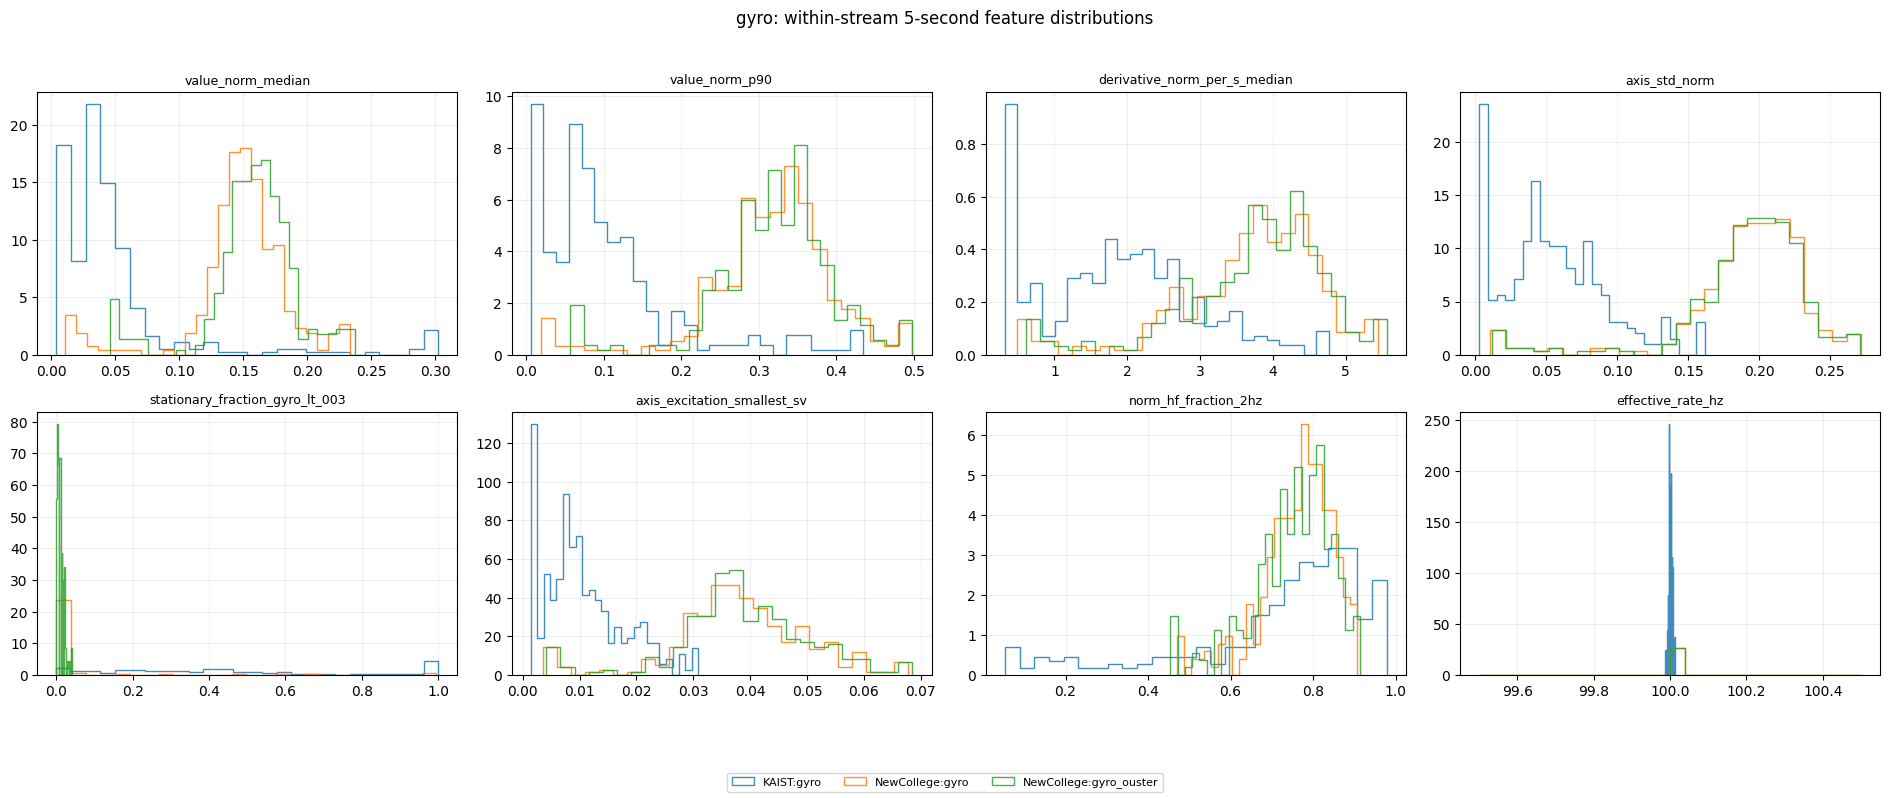

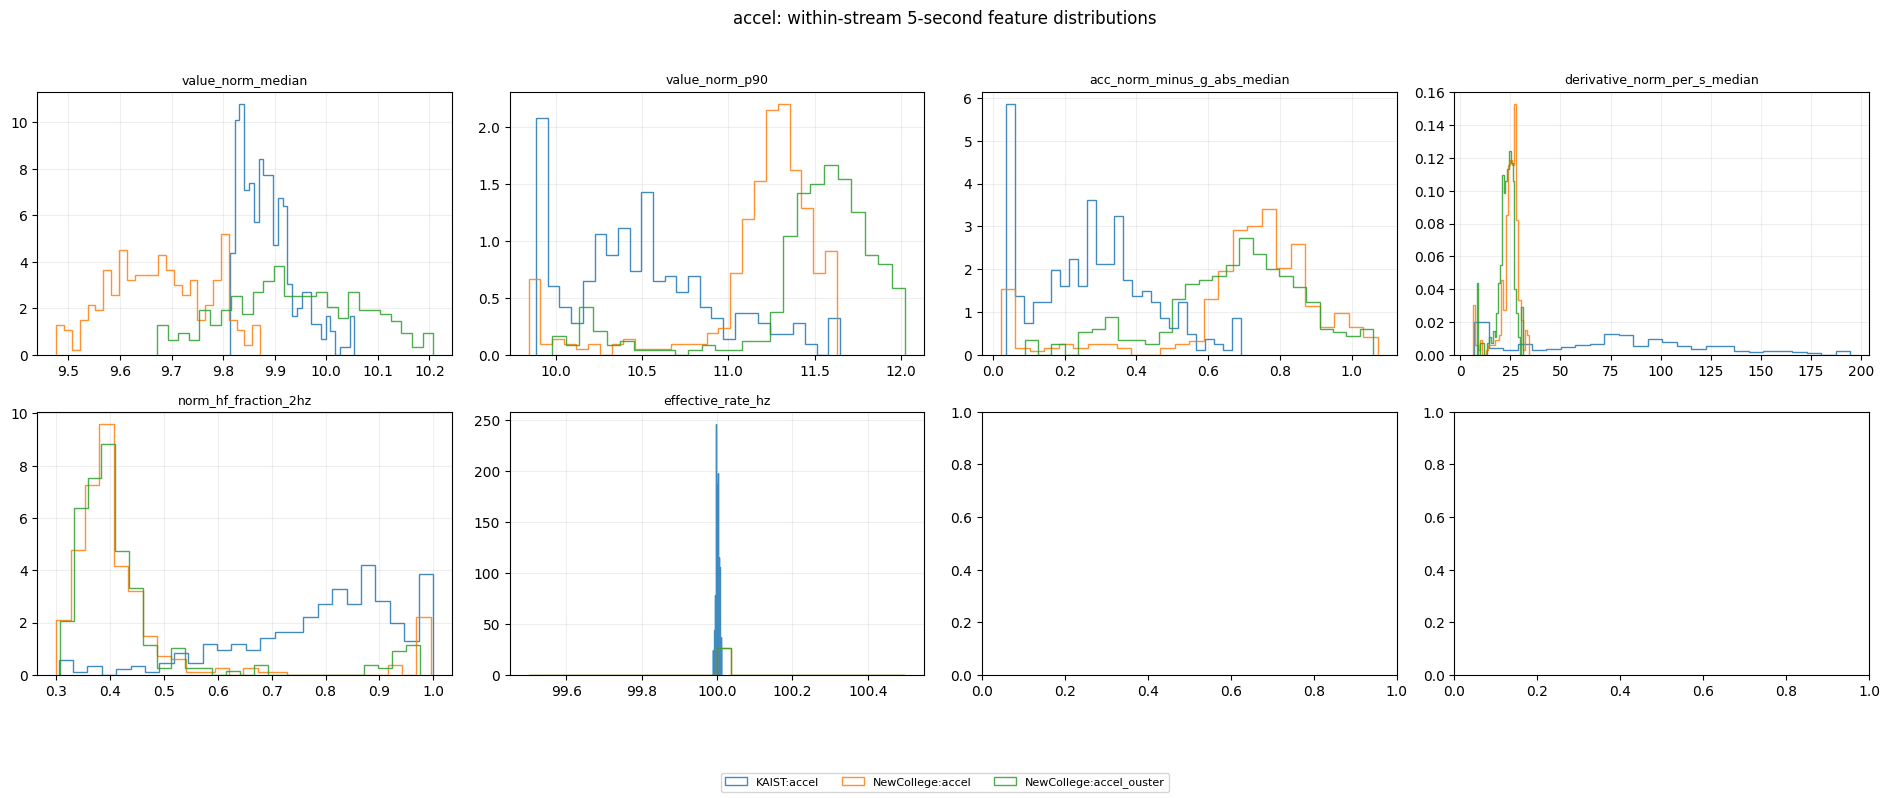

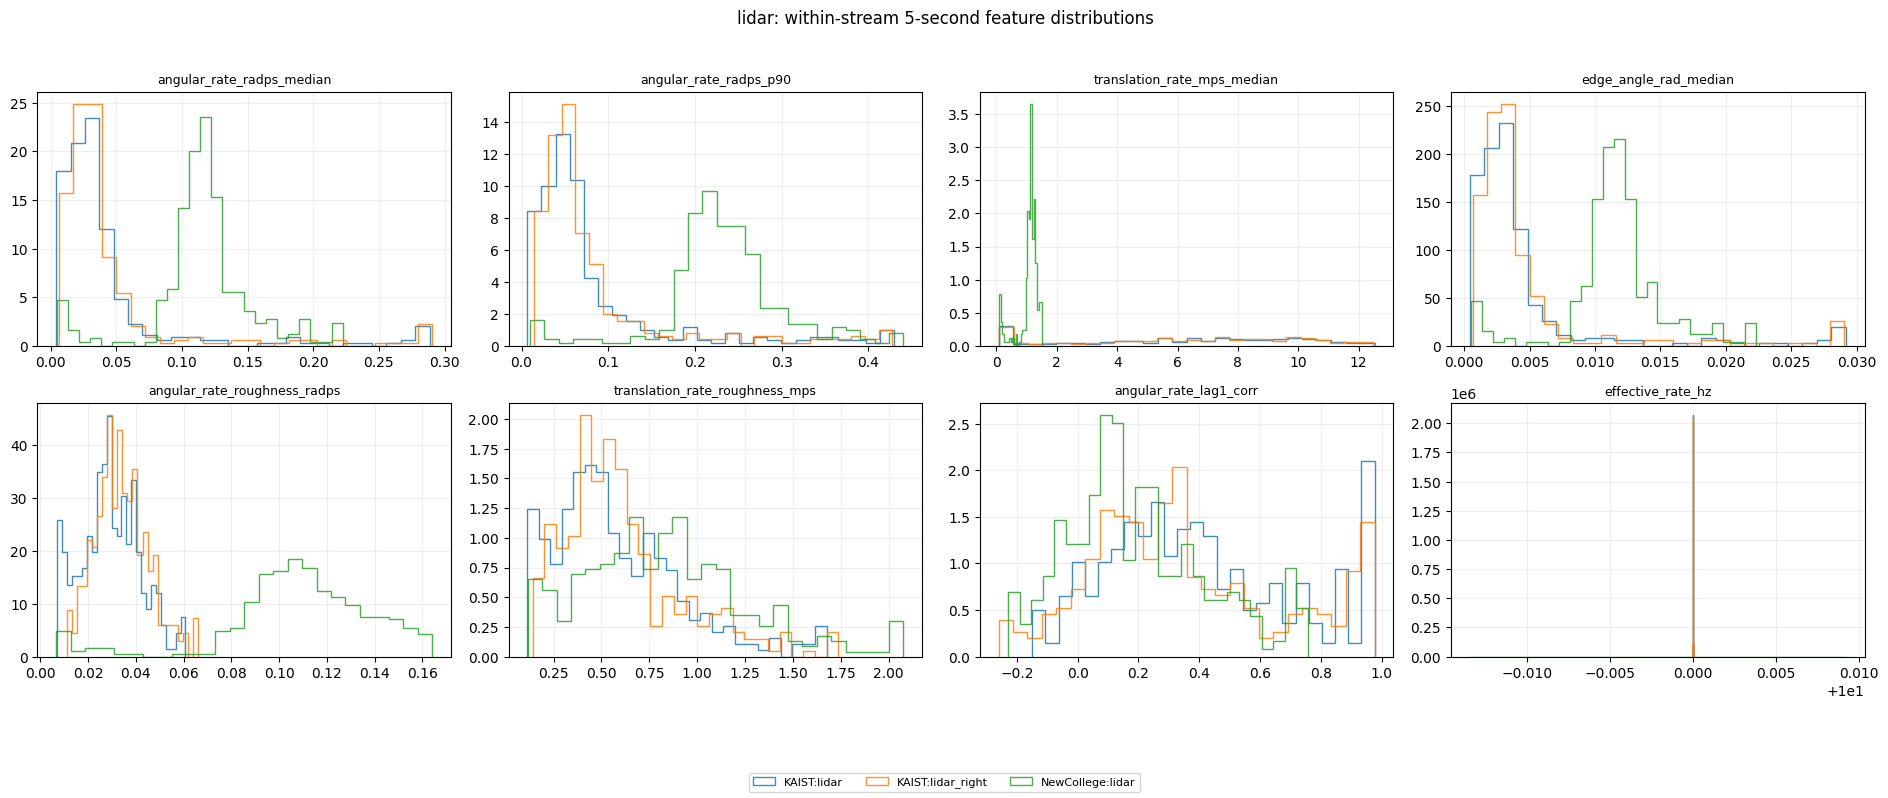

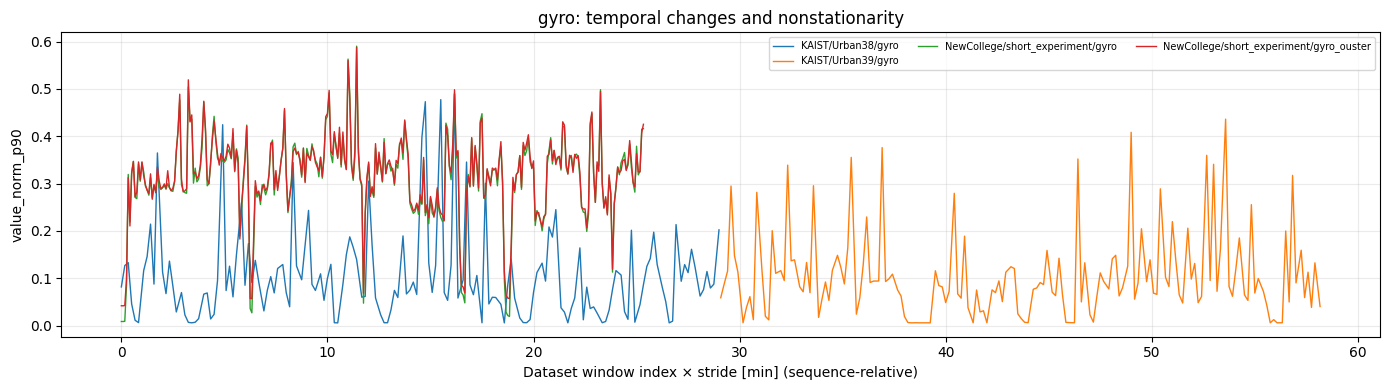

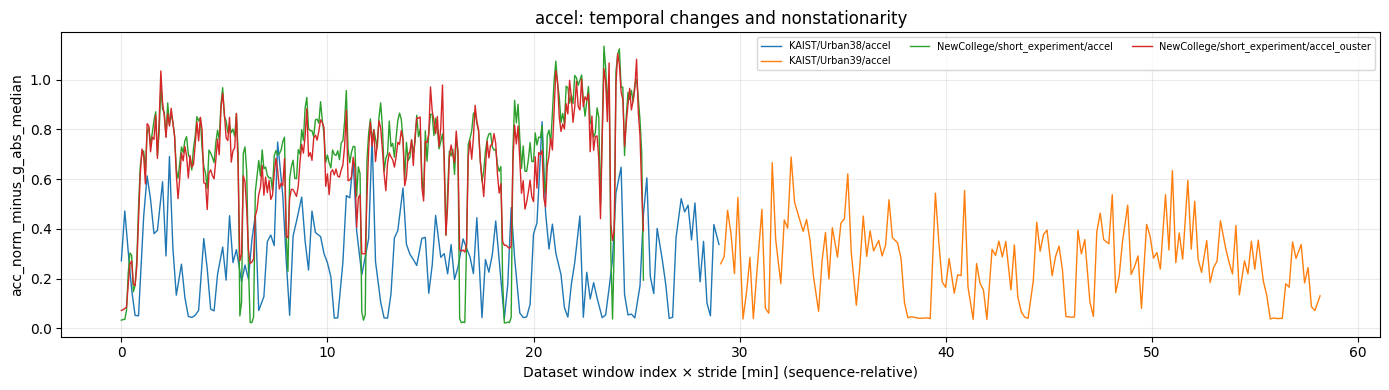

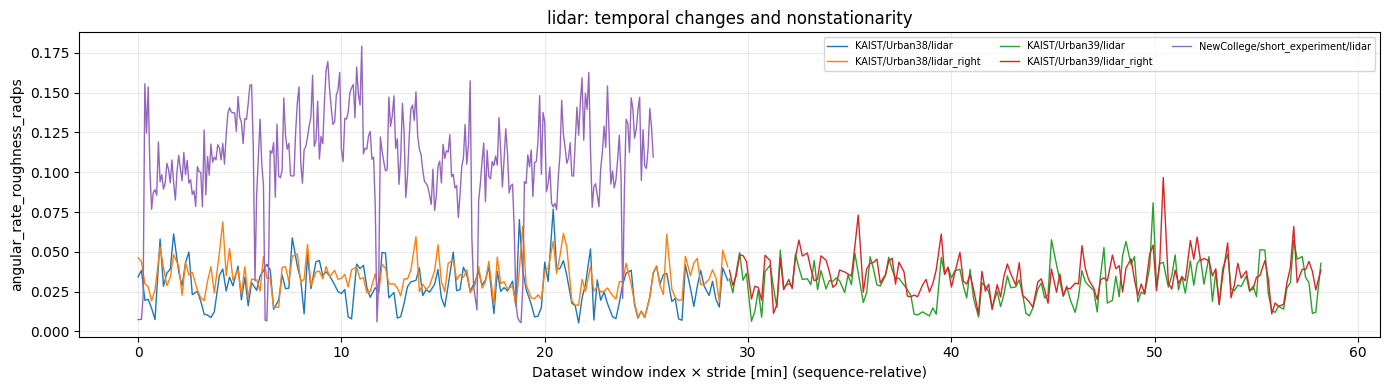

In [49]:
METRICS_BY_MODALITY={
 'gyro':['value_norm_median','value_norm_p90','derivative_norm_per_s_median','axis_std_norm','stationary_fraction_gyro_lt_003','axis_excitation_smallest_sv','norm_hf_fraction_2hz','effective_rate_hz'],
 'accel':['value_norm_median','value_norm_p90','acc_norm_minus_g_abs_median','derivative_norm_per_s_median','norm_hf_fraction_2hz','effective_rate_hz'],
 'lidar':['angular_rate_radps_median','angular_rate_radps_p90','translation_rate_mps_median','edge_angle_rad_median','angular_rate_roughness_radps','translation_rate_roughness_mps','angular_rate_lag1_corr','effective_rate_hz']
}
for modality,metrics in METRICS_BY_MODALITY.items():
    fig,axes=plt.subplots(2,4,figsize=(19,8))
    group=features[features.modality==modality]
    for ax,metric in zip(axes.flat,metrics):
        if metric not in features:continue
        for (dataset,stream),g in group.groupby(['dataset','stream']):
            v=g[metric].to_numpy(dtype=float);v=v[np.isfinite(v)]
            if len(v):
                lo,hi=np.quantile(v,[.01,.99]);v=np.clip(v,lo,hi)
                ax.hist(v,bins=26,density=True,histtype='step',label=f'{dataset}:{stream}',alpha=.85)
        ax.set_title(metric,fontsize=9);ax.grid(alpha=.2)
    handles,labels=axes.flat[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',ncol=min(5,len(labels)),fontsize=8)
    fig.suptitle(f'{modality}: within-stream 5-second feature distributions')
    fig.tight_layout(rect=(0,.10,1,.96))
    if SAVE_FIGURES:fig.savefig(OUT/f'{modality}_feature_distributions.png',dpi=140)
    plt.show();plt.close(fig)

for modality,metric in [('gyro','value_norm_p90'),('accel','acc_norm_minus_g_abs_median'),('lidar','angular_rate_roughness_radps')]:
    fig,ax=plt.subplots(figsize=(14,4))
    group=features[features.modality==modality]
    for (dataset,sequence,stream),g in group.groupby(['dataset','sequence','stream']):
        g=g.sort_values('window_index')
        ax.plot(g.window_index.to_numpy()*WINDOW_STRIDE_S/60,g[metric].to_numpy(),linewidth=1,label=f'{dataset}/{sequence}/{stream}')
    ax.set(xlabel='Dataset window index × stride [min] (sequence-relative)',ylabel=metric,title=f'{modality}: temporal changes and nonstationarity')
    ax.grid(alpha=.25);ax.legend(fontsize=7,ncol=3);fig.tight_layout()
    if SAVE_FIGURES:fig.savefig(OUT/f'{modality}_temporal.png',dpi=140)
    plt.show();plt.close(fig)

## 11. Block-aware statistical comparison

Report KS/Wasserstein and rank-probability effect sizes as **descriptive statistics**. To reduce pseudo-replication from serial correlation, confidence intervals are produced by resampling contiguous groups of `BLOCK_SIZE_WINDOWS` neighboring selected windows (about 30 seconds when no windows are subsampled) separately within each sequence/stream. For interpretability compare **matched physical modalities**; no statistical test can isolate odometry algorithm from all other experimental differences. BH-FDR adjustment is exploratory; block-bootstrap CIs are more important than small naive sample-level p-values.

In [50]:
def contiguous_groups(g,block_size=BLOCK_SIZE_WINDOWS):
    g=g.sort_values('window_index').copy()
    g['resample_block']=(np.arange(len(g))//block_size).astype(int)
    return g

def block_bootstrap_median_difference(a,b,n_boot=BOOTSTRAP_REPEATS,seed=RANDOM_SEED):
    rng_local=np.random.default_rng(seed)
    ba=[z[np.isfinite(z)] for z in a if np.isfinite(z).any()]
    bb=[z[np.isfinite(z)] for z in b if np.isfinite(z).any()]
    if len(ba)<2 or len(bb)<2:return (np.nan,np.nan)
    values=[]
    for _ in range(n_boot):
        x=np.concatenate([ba[j] for j in rng_local.integers(0,len(ba),len(ba))]);y=np.concatenate([bb[j] for j in rng_local.integers(0,len(bb),len(bb))])
        values.append(np.median(y)-np.median(x))
    return tuple(np.quantile(values,[.025,.975]))

def compare_stream_pairs(df,metric,modality):
    sub=df[df.modality==modality].copy()
    pairs=[]
    for (d,s),g in sub.groupby(['dataset','stream']):
        if metric not in g or g[metric].dropna().empty:continue
        pairs.append((d,s,g))
    kaist=[(s,g) for d,s,g in pairs if d=='KAIST']
    newcollege=[(s,g) for d,s,g in pairs if d=='NewCollege']
    rows=[]
    for sn,gn in newcollege:
        for sk,gk in kaist:
            x=gk[metric].dropna().to_numpy(dtype=float);y=gn[metric].dropna().to_numpy(dtype=float)
            if len(x)<5 or len(y)<5:continue
            # Reconstruct separate blocks for each original sequence, without pooling their order.
            blocks_x=[]
            for _,part in gk.groupby('sequence'):
                q=contiguous_groups(part)
                blocks_x += [gg[metric].to_numpy(dtype=float) for _,gg in q.groupby('resample_block')]
            blocks_y=[]
            for _,part in gn.groupby('sequence'):
                q=contiguous_groups(part)
                blocks_y += [gg[metric].to_numpy(dtype=float) for _,gg in q.groupby('resample_block')]
            lo,hi=block_bootstrap_median_difference(blocks_x,blocks_y)
            pooled_iqr=max(np.percentile(np.r_[x,y],75)-np.percentile(np.r_[x,y],25),1e-12)
            # P(NewCollege > KAIST) without materializing large Cartesian products.
            from scipy.stats import mannwhitneyu
            probability=float(mannwhitneyu(y,x,alternative='two-sided').statistic/(len(x)*len(y)))
            rows.append({'modality':modality,'metric':metric,'KAIST_stream':sk,'NewCollege_stream':sn,'n_kaist_windows':len(x),'n_nc_windows':len(y),'KAIST_median':np.median(x),'NewCollege_median':np.median(y),'median_difference_NC_minus_KAIST':np.median(y)-np.median(x),'block_CI_low':lo,'block_CI_high':hi,'KS_stat':float(ks_2samp(x,y).statistic),'KS_p_naive_not_independent':float(ks_2samp(x,y).pvalue),'W1_over_pooled_IQR':wasserstein_distance(x,y)/pooled_iqr,'probability_NC_gt_KAIST':probability})
    return rows

stat_rows=[]
for modality,cols in METRICS_BY_MODALITY.items():
    for metric in cols:stat_rows.extend(compare_stream_pairs(features,metric,modality))
stat_table=pd.DataFrame(stat_rows)
# BH correction for descriptive/naive KS p-values; treat autocorrelation with bootstrap instead.
if len(stat_table):
    p=stat_table.KS_p_naive_not_independent.to_numpy(dtype=float)
    order=np.argsort(p);m=len(p);q=np.empty(m,dtype=float)
    adjusted=np.minimum.accumulate((p[order]*m/np.arange(1,m+1))[::-1])[::-1]
    q[order]=np.minimum(adjusted,1.)
    stat_table['KS_q_naive_BH']=q
    stat_table['block_CI_excludes_zero']=(stat_table.block_CI_low>0)|(stat_table.block_CI_high<0)
    stat_table=stat_table.sort_values(['modality','W1_over_pooled_IQR'],ascending=[True,False])
stat_table.to_csv(OUT/'distribution_comparisons.csv',index=False)
display(stat_table[['modality','metric','KAIST_stream','NewCollege_stream','KAIST_median','NewCollege_median','W1_over_pooled_IQR','probability_NC_gt_KAIST','block_CI_low','block_CI_high','block_CI_excludes_zero']].round(3).head(45))

,modality,metric,KAIST_stream,NewCollege_stream,KAIST_median,NewCollege_median,W1_over_pooled_IQR,probability_NC_gt_KAIST,block_CI_low,block_CI_high,block_CI_excludes_zero
26,accel,effective_rate_hz,accel,accel,100.000,100.000,4.042012e+09,0.467,0.000,0.000,False
27,accel,effective_rate_hz,accel,accel_ouster,100.000,100.000,4.042012e+09,0.467,0.000,0.000,False
16,accel,value_norm_median,accel,accel,9.878,9.676,1.034000e+00,0.016,-0.228,-0.180,True
22,accel,derivative_norm_per_s_median,accel,accel,78.234,25.643,9.760000e-01,0.181,-59.028,-47.457,True
23,accel,derivative_norm_per_s_median,accel,accel_ouster,78.234,23.579,9.660000e-01,0.177,-61.189,-49.676,True
21,accel,acc_norm_minus_g_abs_median,accel,accel_ouster,0.277,0.691,9.190000e-01,0.924,0.362,0.464,True
20,accel,acc_norm_minus_g_abs_median,accel,accel,0.277,0.744,8.280000e-01,0.897,0.424,0.506,True
19,accel,value_norm_p90,accel,accel_ouster,10.475,11.567,8.100000e-01,0.913,1.002,1.207,True
25,accel,norm_hf_fraction_2hz,accel,accel_ouster,0.826,0.392,7.790000e-01,0.086,-0.450,-0.409,True
24,accel,norm_hf_fraction_2hz,accel,accel,0.826,0.392,7.740000e-01,0.091,-0.452,-0.408,True


## 12. Motion-matched comparison (confounding control)

Differences in LiDAR angular-rate roughness may simply reflect different turns. Here both datasets are stratified by LiDAR angular-rate level. Within each bin compare roughness rather than treating changes in trajectory dynamics as registration error. Still not a causal identification of scan-to-scan vs scan-to-map.

,dataset,stream,motion_bin,n,rough_median,motion_median
0,KAIST,lidar,"(0.00197, 0.0245]",122,0.018100,0.014897
1,KAIST,lidar,"(0.0245, 0.039]",105,0.032655,0.030101
2,KAIST,lidar,"(0.039, 0.11]",68,0.037906,0.048315
3,KAIST,lidar,"(0.11, 0.315]",25,0.041009,0.209924
4,KAIST,lidar_right,"(0.00197, 0.0245]",99,0.023026,0.016562
5,KAIST,lidar_right,"(0.0245, 0.039]",128,0.034390,0.030272
6,KAIST,lidar_right,"(0.039, 0.11]",68,0.039946,0.050181
7,KAIST,lidar_right,"(0.11, 0.315]",25,0.046686,0.217958
8,NewCollege,lidar,"(0.00197, 0.0245]",16,0.008221,0.007921
9,NewCollege,lidar,"(0.0245, 0.039]",3,0.031625,0.032811


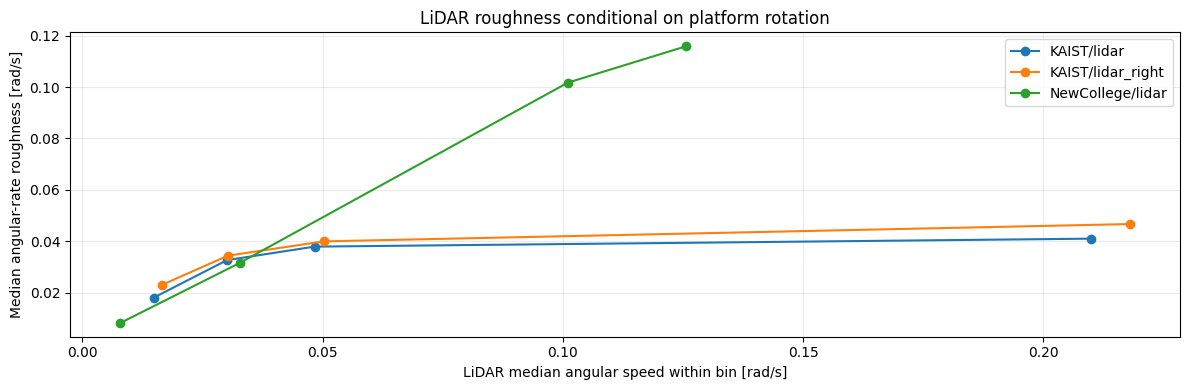

In [51]:
lidar_rows=features[features.modality=='lidar'].copy()
motion_col='angular_rate_radps_median';rough_col='angular_rate_roughness_radps'
lidar_rows=lidar_rows[np.isfinite(lidar_rows[motion_col])&np.isfinite(lidar_rows[rough_col])].copy()
if len(lidar_rows):
    q=np.unique(np.quantile(lidar_rows[motion_col],[0,.25,.5,.75,1.]))
    if len(q)>2:
        lidar_rows['motion_bin']=pd.cut(lidar_rows[motion_col],bins=q,include_lowest=True,duplicates='drop')
        conditioned=lidar_rows.groupby(['dataset','stream','motion_bin'],observed=True).agg(n=('window_index','size'),rough_median=(rough_col,'median'),motion_median=(motion_col,'median')).reset_index()
        display(conditioned)
        conditioned.to_csv(OUT/'lidar_roughness_conditioned_on_motion.csv',index=False)
        fig,ax=plt.subplots(figsize=(12,4))
        for (dataset,stream),g in conditioned.groupby(['dataset','stream']):
            g=g.sort_values('motion_median');ax.plot(g.motion_median,g.rough_median,marker='o',label=f'{dataset}/{stream}')
        ax.set(xlabel='LiDAR median angular speed within bin [rad/s]',ylabel='Median angular-rate roughness [rad/s]',title='LiDAR roughness conditional on platform rotation')
        ax.grid(alpha=.25);ax.legend();fig.tight_layout()
        if SAVE_FIGURES:fig.savefig(OUT/'lidar_roughness_motion_matched.png',dpi=140)
        plt.show();plt.close(fig)

## 12b. NewCollege internal control: RealSense versus Ouster gyroscope

Two IMUs observing the **same rigid body** offer an independent test of clock alignment and extrinsic rotational consistency without using LiDAR odometry at all. Rotate each gyroscope to the common camera frame, sweep the RealSense→Ouster timestamp difference, and measure direction agreement and RMS angular-velocity discrepancy. The shift convention below is `t_Ouster_query = t_RealSense + τ`. Do not interpret the optimum as verified absolute LiDAR clock calibration; neither mounting lever-arm acceleration nor different gyroscope biases are removed.

,shift_s,n_samples,rmse_radps,median_disagreement_radps,median_direction_cosine,p90_disagreement_radps
9,-0.075,15072,0.08071,0.05543,0.95324,0.11296
10,-0.050,15072,0.11211,0.07306,0.93765,0.17212
8,-0.100,15072,0.17736,0.11383,0.86323,0.28257
11,-0.025,15072,0.21180,0.13801,0.77226,0.33986
16,0.100,15072,0.23571,0.18049,0.51018,0.36290
15,0.075,15072,0.24031,0.17381,0.55772,0.37958
3,-0.225,15072,0.24082,0.17604,0.54268,0.37640
2,-0.250,15072,0.24636,0.18600,0.45532,0.38159


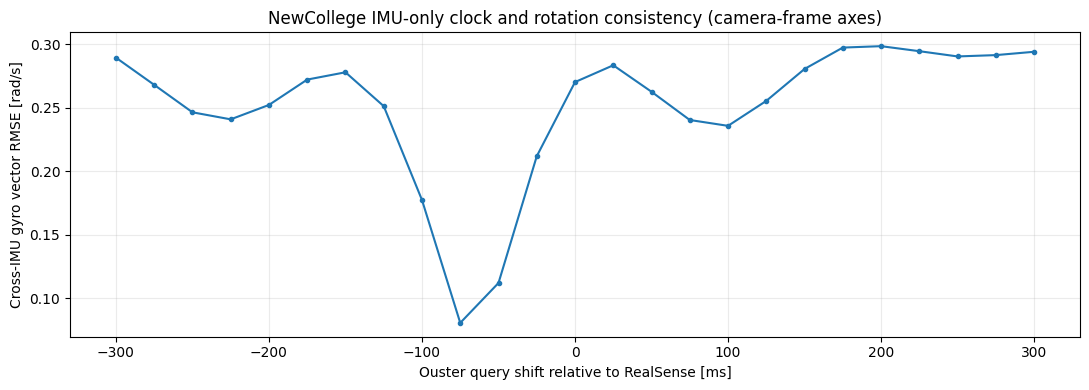

In [52]:
def imu_pair_alignment(t_ref,w_ref,t_other,w_other,R_ref,R_other,shift_values,maximum_samples=16000):
    indices=equally_spaced_indices(np.arange(len(t_ref)),maximum_samples)
    t=t_ref[indices];a=(R_ref@w_ref[indices].T).T
    selected=np.linalg.norm(a,axis=1)>0.03
    results=[]
    for shift in shift_values:
        target=t+shift
        mask=selected&(target>=t_other[0])&(target<=t_other[-1])
        if mask.sum()<100:continue
        b=np.column_stack([np.interp(target[mask],t_other,w_other[:,j]) for j in range(3)])
        b=(R_other@b.T).T
        x=a[mask]
        err=np.linalg.norm(x-b,axis=1)
        norms=np.linalg.norm(x,axis=1)*np.linalg.norm(b,axis=1)
        cos=np.sum(x*b,axis=1)/np.maximum(norms,1e-9)
        results.append({'shift_s':float(shift),'n_samples':len(err),'rmse_radps':float(np.sqrt(np.mean(err**2))),'median_disagreement_radps':float(np.median(err)),'median_direction_cosine':float(np.median(cos)),'p90_disagreement_radps':float(np.percentile(err,90))})
    return pd.DataFrame(results)

imu_control=imu_pair_alignment(rs_ts,rs_gyro,ou_ts,ou_gyro,NC_TRANSFORMS['imu_realsense'][:3,:3],NC_TRANSFORMS['imu_ouster'][:3,:3],TAU_SWEEP_S)
if imu_control.empty:
    warnings.warn('Insufficient overlap/excitation to compare RealSense and Ouster IMUs.')
else:
    best_imu_control=imu_control.loc[imu_control.rmse_radps.idxmin()]
    display(imu_control.sort_values('rmse_radps').head(8).round(5))
    imu_control.to_csv(OUT/'newcollege_imu_to_imu_time_sweep.csv',index=False)
    fig,ax=plt.subplots(figsize=(11,4))
    ax.plot(imu_control.shift_s*1000,imu_control.rmse_radps,marker='.')
    ax.set(xlabel='Ouster query shift relative to RealSense [ms]',ylabel='Cross-IMU gyro vector RMSE [rad/s]',title='NewCollege IMU-only clock and rotation consistency (camera-frame axes)')
    ax.grid(alpha=.25);fig.tight_layout()
    if SAVE_FIGURES:fig.savefig(OUT/'newcollege_imu_to_imu_time_sweep.png',dpi=140)
    plt.show();plt.close(fig)


## 13. Physical consistency of IMU and LiDAR relative rotation

For each actual LiDAR edge on the **same 5 s window**, integrate native gyroscope angular velocities over its interval with an adjustable IMU timestamp shift and compare the resulting relative rotation with LiDAR SE(3) rotation, using the supplied nominal spatial extrinsics. Test both LiDAR edge directions: original and inverse. A failure under *both* conventions can indicate a time mismatch, wrong frame convention, biased IMU, poor LiDAR registration, or nominal-extrinsic error. It does not by itself imply the network is at fault.

`tau_s` below has the **explicit diagnostic convention** `t_IMU_query = t_LiDAR + tau_s`, not necessarily the repository's calibration-parameter sign convention. Candidate comparisons use only edges valid for the full sweep, so different offsets see the *same* edges. The gyro integration uses midpoint/trapezoidal values with Lie-group composition; its approximation error grows for high-frequency motion.

In [53]:
def integrated_gyro_delta(ts,omega,t0,t1):
    ts=np.asarray(ts,dtype=float);omega=np.asarray(omega,dtype=float)
    if len(ts)<2 or not (ts[0]<=t0<t1<=ts[-1]):return None
    interior=ts[(ts>t0)&(ts<t1)]
    knots=np.r_[t0,interior,t1]
    w=np.column_stack([np.interp(knots,ts,omega[:,j]) for j in range(3)])
    inc=Rotation.from_rotvec(.5*(w[1:]+w[:-1])*np.diff(knots)[:,None])
    cumulative=Rotation.identity()
    for item in inc:cumulative=cumulative*item
    return cumulative

def angular_error_deg(a,b):
    return float(np.rad2deg((a.inv()*b).magnitude()))

# Direction and time-integration unit tests.
test_ts=np.linspace(0,2,201)
test_omega=np.tile([0.,0.,.5],(len(test_ts),1))
_r=integrated_gyro_delta(test_ts,test_omega,.3,1.3)
assert _r is not None and np.isclose(_r.magnitude(),.5,atol=1e-5)
assert angular_error_deg(_r,Rotation.from_rotvec([0.,0.,.5]))<1e-5

def selected_windows_for_consistency():
    picked=[]
    for (dataset,sequence),(ds,indices) in DATASET_GROUPS.items():
        for i in equally_spaced_indices(indices,CONSISTENCY_WINDOWS_PER_SEQUENCE):
            picked.append((dataset,sequence,ds,int(i)))
    return picked

def build_physical_pairs(w):
    # Metadata, not name heuristics, determines which IMU and LiDAR share calibration keys.
    gyro={k:m.calibration_key for k,m in w.metadata.items() if k.startswith('gyro')}
    lidar={k:m.calibration_key for k,m in w.metadata.items() if 'lidar' in k}
    return [(g,l,ig,ll) for g,ig in gyro.items() for l,ll in lidar.items()]

def consistency_edges(w,gyro_key,lidar_key):
    gyro_ts,gyro_values,_=valid_stream_arrays(w.streams[gyro_key])
    lidar_ts,lidar_values,lidar_starts=valid_stream_arrays(w.streams[lidar_key])
    if lidar_starts is None:raise ValueError('LiDAR edge interval starts are mandatory')
    tau_max=max(abs(float(x)) for x in TAU_SWEEP_S)
    valid=(lidar_starts>=gyro_ts[0]+tau_max+1e-8)&(lidar_ts<=gyro_ts[-1]-tau_max-1e-8)&(lidar_ts>lidar_starts)
    inds=np.flatnonzero(valid)
    if len(inds)>CONSISTENCY_MAX_EDGES_PER_WINDOW:
        inds=inds[np.unique(np.linspace(0,len(inds)-1,CONSISTENCY_MAX_EDGES_PER_WINDOW).astype(int))]
    return gyro_ts,gyro_values,[(lidar_starts[k],lidar_ts[k],lidar_values[k]) for k in inds]

def T_L_I_for_pair(w,imu_calibration_key,lidar_calibration_key):
    T_BI=np.asarray(w.current_calibration[imu_calibration_key].transform[0],dtype=float)
    T_BL=np.asarray(w.current_calibration[lidar_calibration_key].transform[0],dtype=float)
    return np.linalg.inv(T_BL)@T_BI

def make_consistency_records(dataset,sequence,widx,w):
    records=[]
    for gy,lid,ig,ll in build_physical_pairs(w):
        ti,wi,edges=consistency_edges(w,gy,lid)
        if len(edges)<2:continue
        C=Rotation.from_matrix(T_L_I_for_pair(w,ig,ll)[:3,:3])
        for tau in TAU_SWEEP_S:
            for t0,t1,T in edges:
                rI=integrated_gyro_delta(ti,wi,t0+tau,t1+tau)
                if rI is None:continue
                predicted=C*rI*C.inv()
                observed=Rotation.from_matrix(T[:3,:3])
                for direction,truth in (('as_loaded',observed),('inverse',observed.inv())):
                    edge_rate=truth.magnitude()/(t1-t0)
                    records.append({'dataset':dataset,'sequence':sequence,'window_index':widx,'gyro_stream':gy,'lidar_stream':lid,'imu_key':ig,'lidar_key':ll,'tau_s':float(tau),'pose_direction':direction,'error_deg':angular_error_deg(truth,predicted),'lidar_rate_radps':float(edge_rate),'no_motion_baseline_error_deg':float(np.rad2deg(truth.magnitude())),'duration_s':float(t1-t0)})
    return records

## 14. Execute the time-shift and pose-direction sweep

For efficiency the default uses 14 spaced windows per sequence and up to 12 LiDAR edges per window. Increase after confirming the conventions. Results distinguish all edges from motion-excited edges; near-stationary segments cannot strongly discriminate a wrong rotation/timing convention.

Gyro/LiDAR rotation consistency:   0%|          | 0/42 [00:00<?, ?it/s]

Physical comparisons: 50200 records


,dataset,gyro_stream,lidar_stream,tau_s,pose_direction,n_edges,median_error_deg,mean_error_deg,median_zero_baseline_deg,fraction_better_than_no_motion
0,KAIST,gyro,lidar,-0.050,as_loaded,121,0.1484,0.1700,0.3050,0.5133
1,KAIST,gyro,lidar_right,-0.025,as_loaded,123,0.1347,0.1560,0.3108,0.5664
2,NewCollege,gyro,lidar,0.125,as_loaded,145,0.1912,0.2448,0.7752,0.7533
3,NewCollege,gyro_ouster,lidar,0.075,as_loaded,145,0.3171,0.3689,0.7752,0.5910


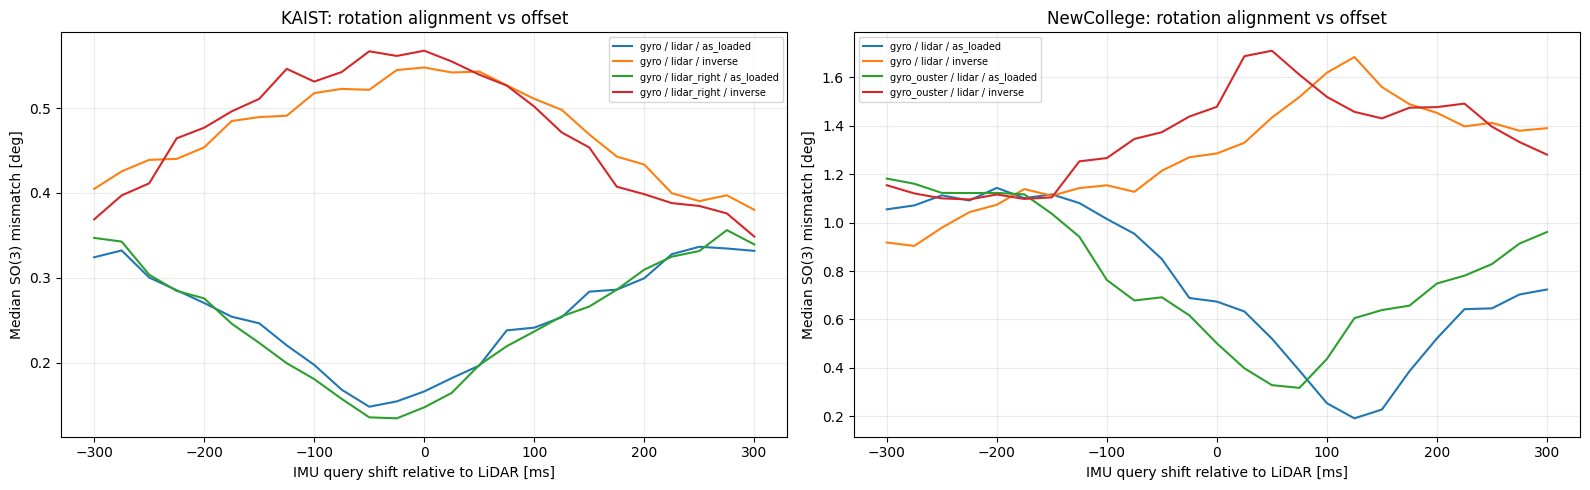

In [54]:
CONSISTENCY_CSV=OUT/'imu_lidar_rotation_consistency_sweep.csv'
consistency=pd.DataFrame()
if RUN_PHYSICAL_CONSISTENCY:
    consistency_rows=[]
    chosen=selected_windows_for_consistency()
    for dataset,sequence,ds,idx in tqdm(chosen,desc='Gyro/LiDAR rotation consistency'):
        consistency_rows.extend(make_consistency_records(dataset,sequence,idx,get_window(ds,idx)))
    consistency=pd.DataFrame(consistency_rows)
    consistency.to_csv(CONSISTENCY_CSV,index=False)
    print('Physical comparisons:',len(consistency),'records')
else:
    print('Physical consistency disabled; set RUN_PHYSICAL_CONSISTENCY=True to enable.')

best_consistency=pd.DataFrame()
if not consistency.empty:
    active=consistency[consistency.lidar_rate_radps>=CONSISTENCY_ACTIVE_RATE_RADPS]
    if len(active)<20:
        warnings.warn('Few rotation-excited edges. Clock/pose-direction minima may not be identifiable.')
    summary=active.groupby(['dataset','gyro_stream','lidar_stream','tau_s','pose_direction']).agg(n_edges=('error_deg','size'),median_error_deg=('error_deg','median'),mean_error_deg=('error_deg','mean'),median_zero_baseline_deg=('no_motion_baseline_error_deg','median')).reset_index()
    summary=summary[summary.n_edges>=5].copy()
    best_consistency=summary.sort_values('median_error_deg').groupby(['dataset','gyro_stream','lidar_stream'],as_index=False).first()
    best_consistency['fraction_better_than_no_motion']=1-best_consistency.median_error_deg/best_consistency.median_zero_baseline_deg.clip(lower=1e-9)
    best_consistency.to_csv(OUT/'imu_lidar_best_alignment.csv',index=False)
    display(best_consistency.round(4))
    fig,axes=plt.subplots(1,2,figsize=(16,5))
    for (dataset,gy,lid,direction),g in summary.groupby(['dataset','gyro_stream','lidar_stream','pose_direction']):
        g=g.sort_values('tau_s')
        ax=axes[0] if dataset=='KAIST' else axes[1]
        ax.plot(g.tau_s*1000,g.median_error_deg,label=f'{gy} / {lid} / {direction}')
    for ax,dat in zip(axes,('KAIST','NewCollege')):
        ax.set(title=f'{dat}: rotation alignment vs offset',xlabel='IMU query shift relative to LiDAR [ms]',ylabel='Median SO(3) mismatch [deg]')
        ax.grid(alpha=.25);ax.legend(fontsize=7)
    fig.tight_layout()
    if SAVE_FIGURES:fig.savefig(OUT/'imu_lidar_time_sweep.png',dpi=140)
    plt.show();plt.close(fig)

## 15. Compare canonicalized model-token distributions (no training)

This uses the **same `GeometryProcessor` and `Tokenizer` as notebooks 32/36**, with each dataset's physical sensor metadata. It diagnoses whether the actual 8-channel Transformer inputs have shifted after geometry processing. Differences here are expected partly from modality counts, so they must be interpreted alongside same-modality physical comparisons. No observability labels or GT calibration corrections are passed to the tokenizer.

Tokens KAIST/Urban38:   0%|          | 0/30 [00:00<?, ?it/s]

Tokens KAIST/Urban39:   0%|          | 0/30 [00:00<?, ?it/s]

Tokens NewCollege/short_experiment:   0%|          | 0/30 [00:00<?, ?it/s]

dataset,KAIST,NewCollege
window_index,348.500,151.500
n_tokens,1097.000,2049.000
token_0_mean,0.019,-0.172
token_0_std,0.471,0.361
token_0_p99abs,1.680,1.217
token_0_fraction_abs_gt5,0.000,0.000
token_1_mean,0.048,-4.840
token_1_std,0.591,5.013
token_1_p99abs,2.396,11.941
token_1_fraction_abs_gt5,0.000,0.488


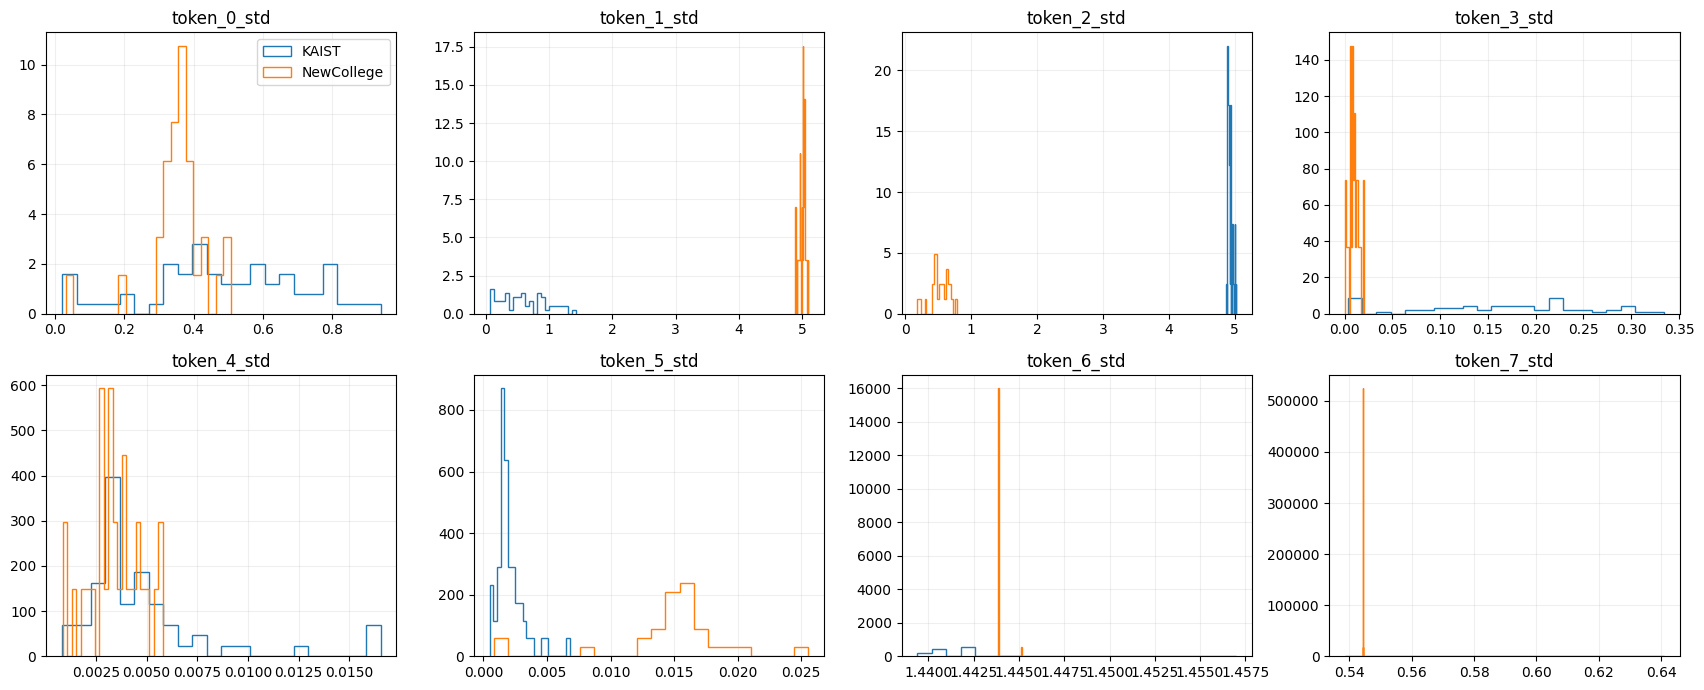

In [55]:
token_stats=pd.DataFrame()
if RUN_TOKEN_DIAGNOSTICS:
    geometry_processor=GeometryProcessor()
    token_rows=[]
    for (dataset,sequence),(ds,indices) in DATASET_GROUPS.items():
        picked=equally_spaced_indices(indices,TOKEN_WINDOWS_PER_SEQUENCE)
        for i in tqdm(picked,desc=f'Tokens {dataset}/{sequence}'):
            w=get_window(ds,i)
            tok=Tokenizer(measurement_dim=6,calibration_keys=tuple(w.current_calibration))
            canonical=geometry_processor(w.streams,w.metadata,w.current_calibration)
            result=tok(canonical,observability=None)
            x=np.asarray(result.x[0].detach().cpu(),dtype=float)
            mask=np.isfinite(x).all(axis=1)
            for field in ('attention_mask','token_mask','valid_mask'):
                value=getattr(result,field,None)
                if isinstance(value,torch.Tensor) and value.shape[-1]==len(mask):
                    mask &= np.asarray(value[0].detach().cpu(),dtype=bool)
            x=x[mask]
            if not len(x):continue
            row={'dataset':dataset,'sequence':sequence,'window_index':int(i),'n_tokens':len(x)}
            for j in range(x.shape[1]):
                row[f'token_{j}_mean']=float(x[:,j].mean())
                row[f'token_{j}_std']=float(x[:,j].std())
                row[f'token_{j}_p99abs']=float(np.quantile(np.abs(x[:,j]),.99))
                row[f'token_{j}_fraction_abs_gt5']=float(np.mean(np.abs(x[:,j])>5))
            token_rows.append(row)
    token_stats=pd.DataFrame(token_rows)
    token_stats.to_csv(OUT/'token_window_statistics.csv',index=False)
    display(token_stats.groupby('dataset').median(numeric_only=True).T.round(3))
    fig,axes=plt.subplots(2,4,figsize=(17,7))
    for j,ax in enumerate(axes.flat):
        name=f'token_{j}_std'
        for d,g in token_stats.groupby('dataset'):
            if name in g:ax.hist(g[name].dropna(),bins=22,density=True,histtype='step',label=d)
        ax.set(title=name);ax.grid(alpha=.2)
    axes.flat[0].legend();fig.tight_layout()
    if SAVE_FIGURES:fig.savefig(OUT/'token_std_distribution.png',dpi=140)
    plt.show();plt.close(fig)

## 16. Optional **frozen** model probe: one-step correction direction

Uses exactly the checkpoint families specified by notebook 32 (002.17 vs 002.15), not the older 002.16 path from a previous NewCollege comparison. For every dataset, initialize all sensors at nominal calibration and perturb **one sensor only**, with the remaining sensors nominal. Predict *one* rotation update, score geodesic improvement and cosine similarity to the ideal local correction. No weights are updated and no GT calibration is passed as a correction target to the network. A bad result here, after successful physical consistency, points toward learned domain shift rather than rollout accumulation alone.

NN probe KAIST/Urban38:   0%|          | 0/5 [00:00<?, ?it/s]

NN probe KAIST/Urban39:   0%|          | 0/5 [00:00<?, ?it/s]

NN probe NewCollege/short_experiment:   0%|          | 0/5 [00:00<?, ?it/s]

improvement_deg  \
dataset    modality model                 perturbation_deg                    
KAIST      imu      Calibration-only      0.0                        -0.080   
                                          15.0                        9.197   
                                          60.0                       53.198   
                    Joint + observability 0.0                        -0.182   
                                          15.0                       10.834   
                                          60.0                       52.858   
           lidar    Calibration-only      0.0                        -0.370   
                                          15.0                        9.105   
                                          60.0                       51.172   
                    Joint + observability 0.0                        -0.594   
                                          15.0                       10.699   
                                          60.0                       52.778   
NewCollege imu      Calibration-only      0.0                       -53.432   
                                          15.0                      -40.578   
                                          60.0                      -10.603   
                    Joint + observability 0.0                       -46.136   
                                          15.0                      -24.281   
                                          60.0                        0.124   
           lidar    Calibration-only      0.0                       -47.500   
                                          15.0                      -30.110   
                                          60.0                       -3.266   
                    Joint + observability 0.0                        -0.346   
                                          15.0                        0.032   
                                          60.0                        0.025   

                                                            predicted_update_deg  \
dataset    modality model                 perturbation_deg                         
KAIST      imu      Calibration-only      0.0                           0.080000   
                                          15.0                         14.630000   
                                          60.0                         58.026001   
                    Joint + observability 0.0                           0.182000   
                                          15.0                         14.997000   
                                          60.0                         57.624001   
           lidar    Calibration-only      0.0                           0.370000   
                                          15.0                         14.524000   
                                          60.0                         56.588001   
                    Joint + observability 0.0                           0.594000   
                                          15.0                         14.506000   
                                          60.0                         57.334000   
NewCollege imu      Calibration-only      0.0                          53.431999   
                                          15.0                         57.147999   
                                          60.0                         49.910000   
                    Joint + observability 0.0                          46.136002   
                                          15.0                         39.075001   
                                          60.0                         11.441000   
           lidar    Calibration-only      0.0                          47.500000   
                                          15.0                         47.203999   
                                          60.0                         45.601002   
                    Joint + observability 0.0                           0

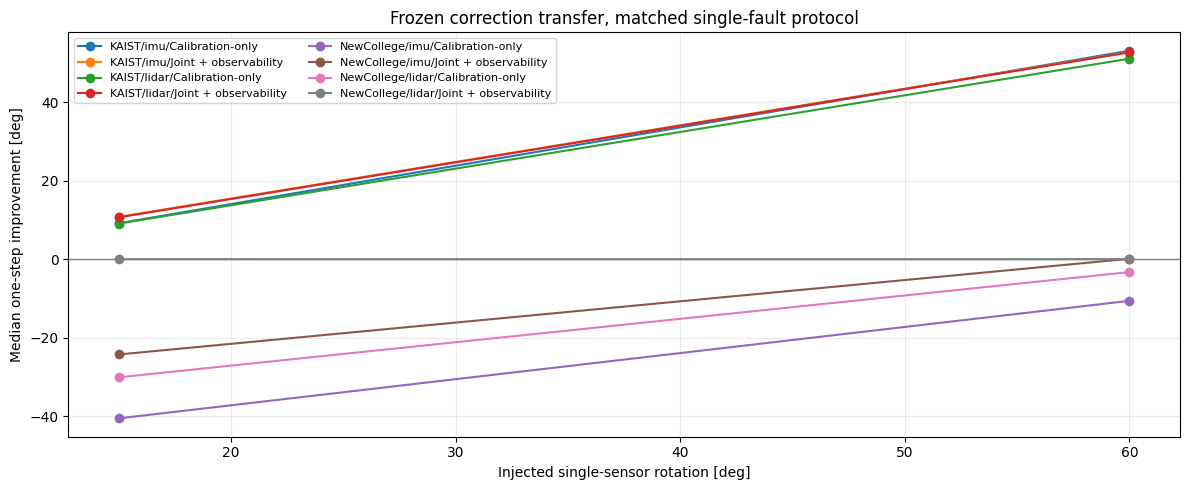

In [56]:
probe=pd.DataFrame()
if RUN_MODEL_PROBE:
    from torch import nn
    from obscalib.config import CalibrationPoolerConfig,MLPConfig,PooledCalibrationHeadConfig,PooledCalibrationModelConfig,TransformerConfig
    from obscalib.models.pooled_calibration_model import PooledCalibrationModel
    from obscalib.training.checkpoint import load_training_checkpoint
    from obscalib.data.device import window_batch_to
    from obscalib.calibration.context import calibration_state_to_context
    from obscalib.geometry.lie import so3_exp

    MODEL_DTYPE=torch.float32
    geometry_processor=GeometryProcessor()  # Independent of RUN_TOKEN_DIAGNOSTICS
    DEVICE=torch.device(DEVICE_NAME if DEVICE_NAME!='cuda' or torch.cuda.is_available() else 'cpu')
    backbone_config=PooledCalibrationModelConfig(transformer=TransformerConfig(input_dim=8,d_model=128,n_heads=8,num_layers=12,dim_feedforward=512,dropout=0.,num_summary_tokens=1,activation='gelu'),mlp=MLPConfig(hidden_dims=(256,128),output_dim=128,activation='gelu',dropout=0.),pooler=CalibrationPoolerConfig(n_heads=8,dropout=0.,calibration_context_dim=0),head=PooledCalibrationHeadConfig(calibration_context_dim=0,hidden_dims=(128,64),activation='gelu',dropout=0.))
    class JointModel(nn.Module):
        def __init__(self):
            super().__init__();self.calibration_model=PooledCalibrationModel(backbone_config);self.observability_head=nn.Sequential(nn.Linear(128,128),nn.GELU(),nn.Linear(128,7),nn.Sigmoid())
        def forward(self,tokens,calibration_context=None):
            output=self.calibration_model(tokens,calibration_context)
            return output,self.observability_head(output.shared_features)

    paths={'Calibration-only':BASELINE_CHECKPOINT,'Joint + observability':OBSERVABILITY_CHECKPOINT}
    models={}
    for label,path in paths.items():
        path=path if path.is_absolute() else ROOT/path
        if not path.is_file():raise FileNotFoundError(f'Missing frozen checkpoint: {path}')
        obj=PooledCalibrationModel(backbone_config) if label=='Calibration-only' else JointModel()
        obj=obj.to(DEVICE,dtype=MODEL_DTYPE)
        load_training_checkpoint(path,model=obj,map_location=DEVICE,restore_rng_state=False)
        obj.eval().requires_grad_(False)
        models[label]=obj if label=='Calibration-only' else obj.calibration_model
    def injected_one_sensor(states,key,axis,angle_deg):
        new={k:CalibrationState(transform=v.transform.clone(),time_offset=v.time_offset.clone()) for k,v in states.items()}
        T=new[key].transform.clone()
        r=torch.zeros((1,3),device=T.device,dtype=T.dtype);r[0,axis]=np.deg2rad(angle_deg)
        T[:,:3,:3]=so3_exp(r)@T[:,:3,:3]
        new[key]=CalibrationState(transform=T,time_offset=new[key].time_offset)
        return new

    rows=[]
    with torch.inference_mode():
        for (dataset,sequence),(ds,indices) in DATASET_GROUPS.items():
            for idx in tqdm(equally_spaced_indices(indices,MODEL_PROBE_WINDOWS_PER_SEQUENCE),desc=f'NN probe {dataset}/{sequence}'):
                w=window_batch_to(get_window(ds,idx),DEVICE,dtype=MODEL_DTYPE)
                nominal=w.current_calibration
                for key in nominal:
                    for angle in MODEL_PROBE_ANGLES_DEG:
                        for axis in (0,1,2):
                            candidate=injected_one_sensor(nominal,key,axis,angle)
                            canonical=geometry_processor(w.streams,w.metadata,candidate)
                            tokens=Tokenizer(measurement_dim=6,calibration_keys=tuple(candidate))(canonical,observability=None)
                            context={k:calibration_state_to_context(v) for k,v in candidate.items()}
                            Rc=np.asarray(candidate[key].transform[0,:3,:3].detach().cpu())
                            Rt=np.asarray(nominal[key].transform[0,:3,:3].detach().cpu())
                            target_rotvec=Rotation.from_matrix(Rt@Rc.T).as_rotvec()
                            for label,model in models.items():
                                output=model(tokens,context)
                                dr=output.predictions[key].delta_xi[0,:3]
                                Rp=so3_exp(dr.unsqueeze(0))[0]@candidate[key].transform[0,:3,:3]
                                R_after=np.asarray(Rp.detach().cpu())
                                before=np.rad2deg(Rotation.from_matrix(Rt@Rc.T).magnitude())
                                after=np.rad2deg(Rotation.from_matrix(Rt@R_after.T).magnitude())
                                delta=np.asarray(dr.detach().cpu())
                                cosine=float(delta@target_rotvec/(np.linalg.norm(delta)*np.linalg.norm(target_rotvec))) if np.linalg.norm(target_rotvec)>1e-8 and np.linalg.norm(delta)>1e-8 else np.nan
                                rows.append({'dataset':dataset,'sequence':sequence,'window_index':int(idx),'sensor':key,'modality':'imu' if key.startswith('imu') else 'lidar','axis':'xyz'[axis],'perturbation_deg':angle,'model':label,'initial_error_deg':before,'final_error_deg':after,'improvement_deg':before-after,'predicted_update_deg':np.rad2deg(np.linalg.norm(delta)),'direction_cosine':cosine})
    probe=pd.DataFrame(rows)
    probe.to_csv(OUT/'frozen_checkpoint_correction_probe.csv',index=False)
    display(probe.groupby(['dataset','modality','model','perturbation_deg'])[['improvement_deg','predicted_update_deg','direction_cosine']].median().round(3))
    fig,ax=plt.subplots(figsize=(12,5))
    for (d,mod,model),g in probe[probe.perturbation_deg>0].groupby(['dataset','modality','model']):
        p=g.groupby('perturbation_deg').improvement_deg.median().sort_index()
        ax.plot(p.index,p.values,marker='o',label=f'{d}/{mod}/{model}')
    ax.axhline(0,color='gray',linewidth=1)
    ax.set(xlabel='Injected single-sensor rotation [deg]',ylabel='Median one-step improvement [deg]',title='Frozen correction transfer, matched single-fault protocol')
    ax.legend(fontsize=8,ncol=2);ax.grid(alpha=.25);fig.tight_layout()
    if SAVE_FIGURES:fig.savefig(OUT/'correction_probe_transfer.png',dpi=140)
    plt.show();plt.close(fig)

## 16b. Common-frame gravity alignment and equivariance test

Estimate quasi-static specific-force directions from nominally calibrated IMUs. Apply the same global SO(3) coordinate-frame change to **all** sensor extrinsics, with an additional yaw-control condition. The physical perturbations and native measurements remain unchanged; compare the frozen model outputs and rotation errors. This is an optional diagnostic that runs after the frozen-checkpoint probe.


KAIST/Urban38: 40 quiet sensor-windows, median directional scatter 2.63 deg
KAIST/Urban39: 39 quiet sensor-windows, median directional scatter 2.18 deg
NewCollege: 80 quiet sensor-windows, median directional scatter 2.26 deg
KAIST specific-force direction: [-0.0076  0.0148  0.9999]
NewCollege specific-force direction: [-0.024  -0.9967  0.0773]
Gravity alignment rotation: 86.41 degrees


Common-frame invariance test:   0%|          | 0/3 [00:00<?, ?it/s]

improvement_deg  \
frame              model                 sensor        perturbation_deg                    
gravity_aligned    Calibration-only      imu_ouster    0.0                       -14.718   
                                                       15.0                        1.252   
                                                       60.0                       40.821   
                                         imu_realsense 0.0                        -4.462   
                                                       15.0                        0.028   
                                                       60.0                       34.895   
                                         lidar         0.0                       -59.620   
                                                       15.0                      -45.521   
                                                       60.0                      -15.336   
                   Joint + observability imu_ouster    0.0                        -0.995   
                                                       15.0                        0.834   
                                                       60.0                       40.665   
                                         imu_realsense 0.0                        -1.427   
                                                       15.0                        1.335   
                                                       60.0                       38.292   
                                         lidar         0.0                       -52.524   
                                                       15.0                      -40.404   
                                                       60.0                      -16.428   
gravity_plus_yaw90 Calibration-only      imu_ouster    0.0                        -0.256   
                                                       15.0                        0.091   
                                                       60.0                       31.149   
                                         imu_realsense 0.0                        -0.304   
                                                       15.0                       -0.061   
                                                       60.0                       35.230   
                                         lidar         0.0                       -26.892   
                                                       15.0                      -15.261   
                                                       60.0                        1.788   
                   Joint + observability imu_ouster    0.0                        -0.615   
                                                       15.0                        6.273   
                                                       60.0                       36.699   
                                         imu_realsense 0.0                        -1.960   
                                                       15.0                        2.910   
                                                       60.0                       33.452   
                                         lidar         0.0                       -11.689   
                                                       15.0                       -3.327   
                                                       60.0                       -3.562   
original           Calibration-only      imu_ouster    0.0                       -60.337   
                                                       15.0                      -38.094   
                                                       60.0                       -4.301   
                                         imu_realsense 0.0                       -51.184   
                                                       15.0                      -34.952   
                                                       60.0                       -4.261   
                         

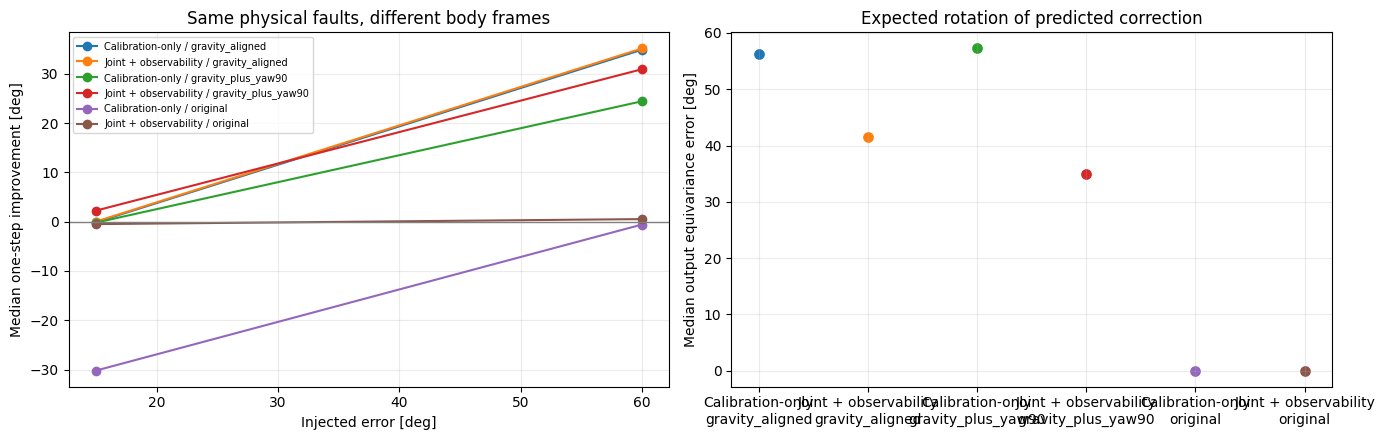

In [57]:
# Notebook 37: insert AFTER the frozen-checkpoint correction-direction probe.
# This is a coordinate-frame invariance diagnostic, not training or self-calibration.
# It reuses the frozen models, GeometryProcessor and injected_one_sensor from the previous cell.

GRAVITY_ESTIMATION_WINDOWS = 40
GRAVITY_PROBE_WINDOWS = 3
GRAVITY_PROBE_KEYS = ('imu_realsense', 'imu_ouster', 'lidar')
GRAVITY_PROBE_ANGLES_DEG = (0.0, 15.0, 60.0)
GRAVITY_PROBE_AXES = (0, 2)
GRAVITY_QUIET_GYRO_RADPS = 0.10
GRAVITY_ACCEL_NORM_TOL_MPS2 = 0.8

if not RUN_MODEL_PROBE or 'models' not in globals():
    print('Run the notebook 37 frozen-model probe first (RUN_MODEL_PROBE=True) to enable gravity-frame testing.')
else:
    def measured_specific_force_direction(dataset, selected_indices, gyro_accel_sensor_keys, label):
        """Robust direction of quasi-static accelerometer specific force in the shared body frame."""
        directions = []
        for index in equally_spaced_indices(selected_indices, GRAVITY_ESTIMATION_WINDOWS):
            window = get_window(dataset, int(index))
            for gyro_name, accel_name, calibration_key in gyro_accel_sensor_keys:
                tg, omega, _ = valid_stream_arrays(window.streams[gyro_name])
                ta, accel, _ = valid_stream_arrays(window.streams[accel_name])
                if len(tg) < 5 or len(ta) < 5:
                    continue
                gyro_norm = np.interp(ta, tg, np.linalg.norm(omega, axis=1))
                mask = (gyro_norm < GRAVITY_QUIET_GYRO_RADPS) & (np.abs(np.linalg.norm(accel, axis=1) - 9.80665) < GRAVITY_ACCEL_NORM_TOL_MPS2)
                if mask.sum() < 20:
                    continue
                R_B_I = np.asarray(window.current_calibration[calibration_key].transform[0, :3, :3], dtype=float)
                a_body = R_B_I @ np.median(accel[mask], axis=0)
                if np.linalg.norm(a_body) > 1e-6:
                    directions.append(a_body / np.linalg.norm(a_body))
        if len(directions) < 5:
            raise RuntimeError(f'{label}: only {len(directions)} quasi-static IMU windows. Increase GRAVITY_ESTIMATION_WINDOWS or inspect the thresholds; do not infer gravity from arbitrary dynamic acceleration.')
        directions = np.asarray(directions)
        mean_direction = np.median(directions, axis=0)
        mean_direction /= np.linalg.norm(mean_direction)
        dispersion_deg = np.rad2deg(np.arccos(np.clip(directions @ mean_direction, -1.0, 1.0)))
        print(f'{label}: {len(directions)} quiet sensor-windows, median directional scatter {np.median(dispersion_deg):.2f} deg')
        return mean_direction

    # One target direction from KAIST and one measured direction from NewCollege.
    kaist_gravity_vectors = [measured_specific_force_direction(kaist_dataset, KAIST_SELECTED[seq], [('gyro', 'accel', 'imu')], f'KAIST/{seq}') for seq in KAIST_SEQUENCES]
    g_kaist = np.median(kaist_gravity_vectors, axis=0)
    g_kaist /= np.linalg.norm(g_kaist)
    g_newcollege = measured_specific_force_direction(nc_dataset, NC_SELECTED, [('gyro', 'accel', 'imu_realsense'), ('gyro_ouster', 'accel_ouster', 'imu_ouster')], 'NewCollege')

    # A maps the NewCollege specific-force direction onto the KAIST one.
    # Gravity fixes only two rotational DOFs. Add a 90-degree yaw control to test the remaining DOF.
    A_gravity = Rotation.align_vectors(g_kaist[None, :], g_newcollege[None, :])[0].as_matrix()
    A_yaw = Rotation.from_rotvec(np.deg2rad(90.0) * g_kaist).as_matrix() @ A_gravity
    np.testing.assert_allclose(A_gravity @ g_newcollege, g_kaist, atol=1e-8)
    print('KAIST specific-force direction:', np.round(g_kaist, 4))
    print('NewCollege specific-force direction:', np.round(g_newcollege, 4))
    print('Gravity alignment rotation:', round(np.rad2deg(Rotation.from_matrix(A_gravity).magnitude()), 2), 'degrees')

    FRAME_ROTATIONS = {'original': np.eye(3), 'gravity_aligned': A_gravity, 'gravity_plus_yaw90': A_yaw}

    def change_common_body_frame(states, A):
        """Left-multiply ALL sensor extrinsics by one SE(3) frame change; leave raw data and tau intact."""
        transformed = {}
        for key, state in states.items():
            H = torch.eye(4, device=state.transform.device, dtype=state.transform.dtype)
            H[:3, :3] = torch.as_tensor(A, device=H.device, dtype=H.dtype)
            transformed[key] = CalibrationState(transform=H.unsqueeze(0) @ state.transform, time_offset=state.time_offset.clone())
        return transformed

    # A gauge change must preserve all relative inter-sensor extrinsics.
    check_states = nc_dataset[0].current_calibration
    aligned_states = change_common_body_frame(check_states, A_gravity)
    for key_a in NC_KEYS:
        for key_b in NC_KEYS:
            old_relative = torch.linalg.inv(check_states[key_a].transform) @ check_states[key_b].transform
            new_relative = torch.linalg.inv(aligned_states[key_a].transform) @ aligned_states[key_b].transform
            torch.testing.assert_close(new_relative, old_relative, rtol=1e-5, atol=1e-5)

    def predict_rotation_update(window, candidate_states, key):
        canonical = geometry_processor(window.streams, window.metadata, candidate_states)
        tokens = Tokenizer(measurement_dim=6, calibration_keys=tuple(candidate_states))(canonical, observability=None)
        context = {name: calibration_state_to_context(state) for name, state in candidate_states.items()}
        return {label: np.asarray(model(tokens, context).predictions[key].delta_xi[0, :3].detach().cpu(), dtype=float) for label, model in models.items()}

    gravity_rows = []
    with torch.inference_mode():
        for index in tqdm(equally_spaced_indices(NC_SELECTED, GRAVITY_PROBE_WINDOWS), desc='Common-frame invariance test'):
            window = window_batch_to(get_window(nc_dataset, int(index)), DEVICE, dtype=MODEL_DTYPE)
            nominal = window.current_calibration
            for key in GRAVITY_PROBE_KEYS:
                for angle in GRAVITY_PROBE_ANGLES_DEG:
                    for axis in GRAVITY_PROBE_AXES:
                        # Create the physical fault ONCE; apply the same gauge change to both truth and candidate.
                        candidate = injected_one_sensor(nominal, key, axis, angle)
                        predictions_by_frame = {}
                        for frame_label, A in FRAME_ROTATIONS.items():
                            reference_f = change_common_body_frame(nominal, A)
                            candidate_f = change_common_body_frame(candidate, A)
                            predictions_by_frame[frame_label] = predict_rotation_update(window, candidate_f, key)
                            R_ref = np.asarray(reference_f[key].transform[0, :3, :3].detach().cpu(), dtype=float)
                            R_now = np.asarray(candidate_f[key].transform[0, :3, :3].detach().cpu(), dtype=float)
                            target = Rotation.from_matrix(R_ref @ R_now.T).as_rotvec()
                            initial_deg = np.rad2deg(Rotation.from_matrix(R_ref @ R_now.T).magnitude())
                            for model_label, dr in predictions_by_frame[frame_label].items():
                                R_updated = Rotation.from_rotvec(dr).as_matrix() @ R_now
                                final_deg = np.rad2deg(Rotation.from_matrix(R_ref @ R_updated.T).magnitude())
                                direction_cosine = float(dr @ target / (np.linalg.norm(dr) * np.linalg.norm(target))) if np.linalg.norm(dr) > 1e-8 and np.linalg.norm(target) > 1e-8 else np.nan
                                gravity_rows.append({'window_index': int(index), 'sensor': key, 'axis': 'xyz'[axis], 'perturbation_deg': angle, 'frame': frame_label, 'model': model_label, 'initial_error_deg': initial_deg, 'final_error_deg': final_deg, 'improvement_deg': initial_deg - final_deg, 'update_deg': np.rad2deg(np.linalg.norm(dr)), 'direction_cosine': direction_cosine})

                        # Vector output should rotate with A if the model is SO(3)-equivariant.
                        for model_label in models:
                            original_dr = predictions_by_frame['original'][model_label]
                            for frame_label, A in FRAME_ROTATIONS.items():
                                predicted_dr = predictions_by_frame[frame_label][model_label]
                                equivariance_error = np.rad2deg(np.linalg.norm(predicted_dr - A @ original_dr))
                                for row in gravity_rows[-len(models)*len(FRAME_ROTATIONS):]:
                                    if row['window_index'] == int(index) and row['sensor'] == key and row['axis'] == 'xyz'[axis] and row['perturbation_deg'] == angle and row['frame'] == frame_label and row['model'] == model_label:
                                        row['equivariance_vector_error_deg'] = equivariance_error

    gravity_frame_results = pd.DataFrame(gravity_rows)
    gravity_frame_results.to_csv(OUT / 'newcollege_gravity_frame_invariance.csv', index=False)
    display(gravity_frame_results.groupby(['frame', 'model', 'sensor', 'perturbation_deg'])[['improvement_deg', 'update_deg', 'direction_cosine', 'equivariance_vector_error_deg']].median().round(3))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for (frame, model_label), part in gravity_frame_results[gravity_frame_results.perturbation_deg > 0].groupby(['frame', 'model']):
        medians = part.groupby('perturbation_deg').improvement_deg.median().sort_index()
        axes[0].plot(medians.index, medians.values, marker='o', label=f'{model_label} / {frame}')
    axes[0].axhline(0, color='gray', linewidth=1)
    axes[0].set(xlabel='Injected error [deg]', ylabel='Median one-step improvement [deg]', title='Same physical faults, different body frames')
    for (frame, model_label), part in gravity_frame_results.groupby(['frame', 'model']):
        axes[1].scatter([f'{model_label}\n{frame}'], [part.equivariance_vector_error_deg.median()], s=45)
    axes[1].set(ylabel='Median output equivariance error [deg]', title='Expected rotation of predicted correction')
    for ax in axes:
        ax.grid(alpha=0.25)
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(OUT / 'newcollege_gravity_frame_invariance.png', dpi=140)
    plt.show()
    plt.close(fig)


KAIST frame invariance: Urban38:   0%|          | 0/4 [00:00<?, ?it/s]

KAIST frame invariance: Urban39:   0%|          | 0/4 [00:00<?, ?it/s]

improvement_deg  \
frame    model                 sensor      initial_angle_deg                    
combined Calibration-only      imu         0.0                        -62.036   
                                           15.0                       -54.194   
                                           60.0                       -21.530   
                               lidar       0.0                         -0.133   
                                           15.0                        -0.030   
...                                                                       ...   
yaw90    Joint + observability lidar       15.0                       -44.078   
                                           60.0                         1.313   
                               lidar_right 0.0                        -71.861   
                                           15.0                       -44.127   
                                           60.0                        -7.505   

                                                              update_deg  \
frame    model                 sensor      initial_angle_deg               
combined Calibration-only      imu         0.0                 62.035999   
                                           15.0                60.473000   
                                           60.0                51.962002   
                               lidar       0.0                  0.133000   
                                           15.0                 0.131000   
...                                                                  ...   
yaw90    Joint + observability lidar       15.0                72.394997   
                                           60.0                69.818001   
                               lidar_right 0.0                 71.861000   
                                           15.0                72.064003   
                                           60.0                69.930000   

                                                              equivariance_error_deg  
frame    model                 sensor      initial_angle_deg                          
combined Calibration-only      imu         0.0                                62.162  
                                           15.0                               70.479  
                                           60.0                               78.558  
                               lidar       0.0                                 0.559  
                                           15.0                                9.204  
...                                                                              ...  
yaw90    Joint + observability lidar       15.0                               59.582  
                                           60.0                               29.517  
                               lidar_right 0.0                                71.688  
                                           15.0                               59.503  
                                           60.0                               36.740  

[72 rows x 3 columns]

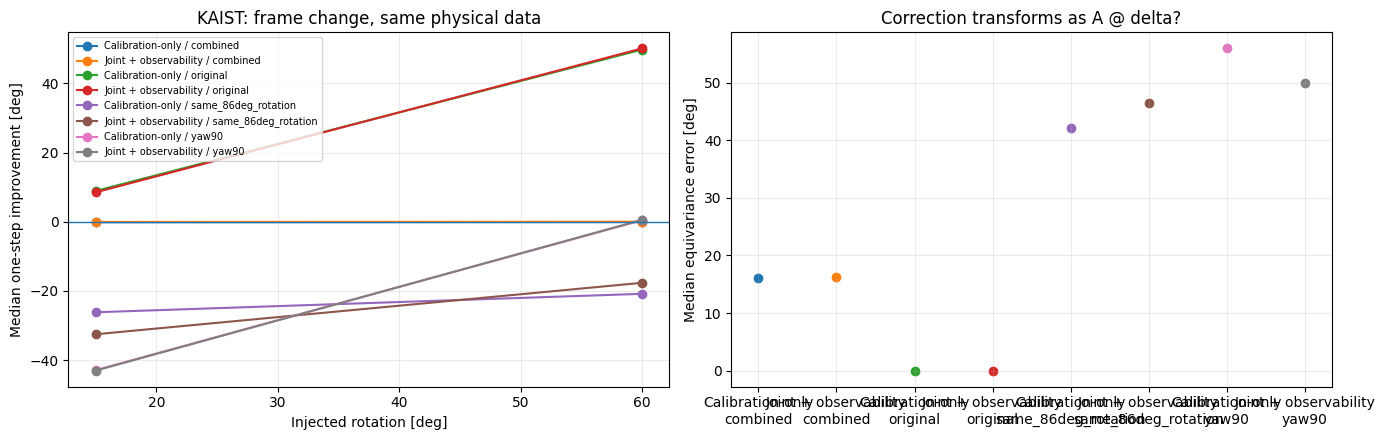

In [59]:
# Insert after notebook 37's frozen-checkpoint model probe.
# Compares the SAME KAIST measurements and SAME physical perturbations in several body frames.
assert 'models' in globals() and 'kaist_dataset' in globals(), 'Run the frozen-model probe first.'

FRAME_TEST_WINDOWS_PER_SEQUENCE = 4
FRAME_TEST_ANGLES_DEG = (0., 15., 60.)
FRAME_TEST_AXES = (0, 2)

# Reuse the exact NewCollege->KAIST frame rotation, if the earlier gravity test was run.
A_shared = globals().get('A_gravity', Rotation.from_rotvec(np.deg2rad(86.41) * np.array([1., 0., 0.])).as_matrix())
A_yaw = Rotation.from_euler('z', 90, degrees=True).as_matrix()
FRAME_TEST_ROTATIONS = {'original': np.eye(3), 'same_86deg_rotation': A_shared, 'yaw90': A_yaw, 'combined': A_yaw @ A_shared}


def frame_transform_states(states, A):
    H = torch.eye(4, device=next(iter(states.values())).transform.device, dtype=next(iter(states.values())).transform.dtype)
    H[:3, :3] = torch.as_tensor(A, device=H.device, dtype=H.dtype)
    return {key: CalibrationState(transform=H.unsqueeze(0) @ state.transform, time_offset=state.time_offset.clone()) for key, state in states.items()}


def run_frozen_rotation_predictions(window, states, selected_key):
    canonical = geometry_processor(window.streams, window.metadata, states)
    tokens = Tokenizer(measurement_dim=6, calibration_keys=tuple(states))(canonical, observability=None)
    context = {key: calibration_state_to_context(state) for key, state in states.items()}
    return {label: model(tokens, context).predictions[selected_key].delta_xi[0, :3].detach().cpu().numpy() for label, model in models.items()}


def rotation_diagnostics(reference, candidate, delta):
    R_true = np.asarray(reference, dtype=np.float64)
    R_current = np.asarray(candidate, dtype=np.float64)
    target = Rotation.from_matrix(R_true @ R_current.T).as_rotvec()
    R_updated = Rotation.from_rotvec(delta).as_matrix() @ R_current
    before = np.rad2deg(Rotation.from_matrix(R_true @ R_current.T).magnitude())
    after = np.rad2deg(Rotation.from_matrix(R_true @ R_updated.T).magnitude())
    cosine = float(np.dot(delta, target) / (np.linalg.norm(delta) * np.linalg.norm(target))) if np.linalg.norm(delta) > 1e-10 and np.linalg.norm(target) > 1e-10 else np.nan
    return before, after, cosine


kaist_frame_rows = []
with torch.inference_mode():
    for sequence in KAIST_SEQUENCES:
        indices = equally_spaced_indices(KAIST_SELECTED[sequence], FRAME_TEST_WINDOWS_PER_SEQUENCE)
        for index in tqdm(indices, desc=f'KAIST frame invariance: {sequence}'):
            window = window_batch_to(get_window(kaist_dataset, int(index)), DEVICE, dtype=MODEL_DTYPE)
            nominal = window.current_calibration
            for sensor in nominal:
                for angle in FRAME_TEST_ANGLES_DEG:
                    for axis in FRAME_TEST_AXES:
                        # Inject once in the original body frame, THEN change the frame.
                        candidate = injected_one_sensor(nominal, sensor, axis, angle)
                        predictions = {}
                        for frame, A in FRAME_TEST_ROTATIONS.items():
                            ref_f = frame_transform_states(nominal, A)
                            cand_f = frame_transform_states(candidate, A)
                            for other in nominal:
                                torch.testing.assert_close(torch.linalg.inv(ref_f[other].transform) @ cand_f[other].transform, torch.linalg.inv(nominal[other].transform) @ candidate[other].transform, atol=1e-5, rtol=1e-5)
                            pred = run_frozen_rotation_predictions(window, cand_f, sensor)
                            predictions[frame] = pred
                            R_true = ref_f[sensor].transform[0, :3, :3].detach().cpu().numpy()
                            R_current = cand_f[sensor].transform[0, :3, :3].detach().cpu().numpy()
                            for model_name, delta in pred.items():
                                before, after, cosine = rotation_diagnostics(R_true, R_current, delta)
                                kaist_frame_rows.append({'sequence': sequence, 'window_index': int(index), 'sensor': sensor, 'axis': 'xyz'[axis], 'initial_angle_deg': angle, 'frame': frame, 'model': model_name, 'initial_error_deg': before, 'final_error_deg': after, 'improvement_deg': before - after, 'update_deg': np.rad2deg(np.linalg.norm(delta)), 'direction_cosine': cosine})
                        for frame, A in FRAME_TEST_ROTATIONS.items():
                            for model_name, delta in predictions[frame].items():
                                expected_delta = A @ predictions['original'][model_name]
                                # Compare physical applied SO(3) corrections, not only rotvec components.
                                discrepancy = Rotation.from_rotvec(delta).inv() * Rotation.from_rotvec(expected_delta)
                                equiv_error = np.rad2deg(discrepancy.magnitude())
                                for row in kaist_frame_rows[-len(models)*len(FRAME_TEST_ROTATIONS):]:
                                    if row['frame'] == frame and row['model'] == model_name:
                                        row['equivariance_error_deg'] = float(equiv_error)

kaist_frame_results = pd.DataFrame(kaist_frame_rows)
kaist_frame_results.to_csv(OUT / 'kaist_common_frame_equivariance.csv', index=False)
display(kaist_frame_results.groupby(['frame', 'model', 'sensor', 'initial_angle_deg'])[['improvement_deg', 'update_deg', 'equivariance_error_deg']].median().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (frame, model_name), subset in kaist_frame_results[kaist_frame_results.initial_angle_deg > 0].groupby(['frame', 'model']):
    values = subset.groupby('initial_angle_deg').improvement_deg.median()
    axes[0].plot(values.index, values.values, marker='o', label=f'{model_name} / {frame}')
axes[0].axhline(0, linewidth=1)
axes[0].set(xlabel='Injected rotation [deg]', ylabel='Median one-step improvement [deg]', title='KAIST: frame change, same physical data')
for (frame, model_name), subset in kaist_frame_results.groupby(['frame', 'model']):
    axes[1].scatter([f'{model_name}\n{frame}'], [subset.equivariance_error_deg.median()])
axes[1].set(ylabel='Median equivariance error [deg]', title='Correction transforms as A @ delta?')
for ax in axes:
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=7)
fig.tight_layout()
if SAVE_FIGURES:
    fig.savefig(OUT / 'kaist_common_frame_equivariance.png', dpi=150)
plt.show()


Physical one-IMU/one-LiDAR comparisons:   0%|          | 0/6 [00:00<?, ?it/s]

improvement_deg  \
dataset    imu           lidar selected_modality context           model                 perturbation_deg                    
KAIST      imu           lidar imu               full_rig          Calibration-only      0.0                        -0.116   
                                                                                         15.0                        7.746   
                                                                                         60.0                       52.947   
                                                                   Joint + observability 0.0                        -0.182   
                                                                                         15.0                        6.563   
...                                                                                                                    ...   
NewCollege imu_realsense lidar lidar             one_imu_one_lidar Calibration-only      15.0                       -1.505   
                                                                                         60.0                        1.258   
                                                                   Joint + observability 0.0                        -0.142   
                                                                                         15.0                        0.056   
                                                                                         60.0                        0.045   

                                                                                                           update_deg  \
dataset    imu           lidar selected_modality context           model                 perturbation_deg               
KAIST      imu           lidar imu               full_rig          Calibration-only      0.0                    0.116   
                                                                                         15.0                  15.336   
                                                                                         60.0                  58.716   
                                                                   Joint + observability 0.0                    0.182   
                                                                                         15.0                  15.093   
...                                                                                                               ...   
NewCollege imu_realsense lidar lidar             one_imu_one_lidar Calibration-only      15.0                  17.438   
                                                                                         60.0                  16.605   
                                                                   Joint + observability 0.0                    0.142   
                                                                                         15.0                   0.142   
                                                                                         60.0                   0.140   

                                                                                                           direction_cosine  \
dataset    imu           lidar selected_modality context           model                 perturbation_deg                     
KAIST      imu           lidar imu               full_rig          Calibration-only      0.0                            NaN   
                                                                                         15.0                         0.994   
                                                                                         60.0                         0.995   
                                                                   Joint + observability 0.0                            NaN   
                                                                                         15.0                         0.996   
...  

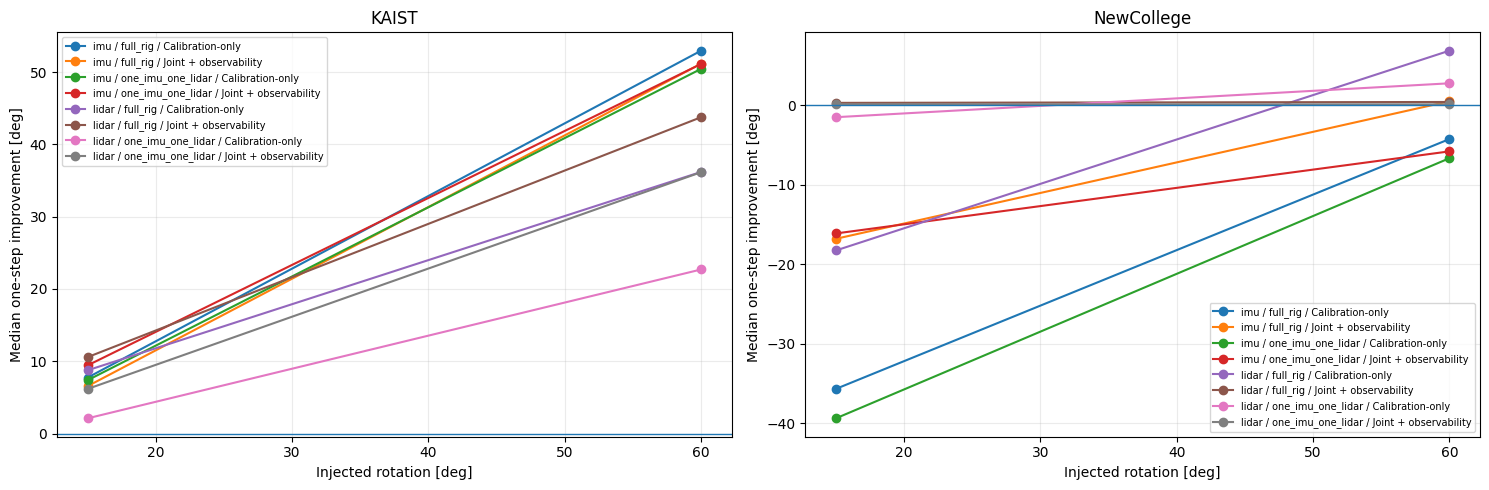

In [60]:
# Insert after the frozen-model probe, optionally after the KAIST frame-invariance cell.
# For each sensor pair, compare exactly the same physical perturbation under full-rig and pair-only inputs.
assert 'models' in globals() and 'injected_one_sensor' in globals(), 'Run the frozen-model probe first.'

PAIR_PROBE_WINDOWS_PER_SEQUENCE = 2  # Increase to 5-10 after the initial run succeeds.
PAIR_PROBE_ANGLES_DEG = (0., 15., 60.)
PAIR_PROBE_AXES = (0, 2)

# Two alternatives per dataset, always retaining ONE real IMU and ONE real LiDAR.
PAIR_SPECS = {
    'KAIST': [('imu', 'lidar'), ('imu', 'lidar_right')],
    'NewCollege': [('imu_realsense', 'lidar'), ('imu_ouster', 'lidar')],
}


def subset_sensor_window(window, states, retained_keys):
    retained_keys = tuple(key for key in states if key in retained_keys)
    streams = {name: stream for name, stream in window.streams.items() if window.metadata[name].calibration_key in retained_keys}
    metadata = {name: window.metadata[name] for name in streams}
    calibration = {key: states[key] for key in retained_keys}
    assert len(calibration) == 2 and len(streams) == 3, f'Expected one IMU gyro+accel and one LiDAR: {retained_keys} / {tuple(streams)}'
    assert sum('gyro' in name for name in streams) == 1 and sum('accel' in name for name in streams) == 1 and sum('lidar' in name for name in streams) == 1
    return replace(window, streams=streams, metadata=metadata, current_calibration=calibration)


def pair_model_predictions(window, states, selected_key):
    canonical = geometry_processor(window.streams, window.metadata, states)
    tokenizer = Tokenizer(measurement_dim=6, calibration_keys=tuple(states))
    tokens = tokenizer(canonical, observability=None)
    assert tuple(tokens.calibration_keys) == tuple(states)
    context = {key: calibration_state_to_context(state) for key, state in states.items()}
    predictions = {}
    for label, model in models.items():
        output = model(tokens, context)
        prediction = output.predictions[selected_key]
        predictions[label] = {
            'rotation': prediction.delta_xi[0, :3].detach().cpu().numpy(),
            'tau_s': float(prediction.delta_tau.detach().cpu().reshape(-1)[0]),
            'n_tokens': int(tokens.x.shape[1]),
        }
    return predictions


PAIR_CASES = []
for dataset_name, sequences in (('KAIST', [(seq, kaist_dataset, KAIST_SELECTED[seq]) for seq in KAIST_SEQUENCES]), ('NewCollege', [('short_experiment', nc_dataset, NC_SELECTED)])):
    for sequence, dataset, available_indices in sequences:
        for imu_key, lidar_key in PAIR_SPECS[dataset_name]:
            PAIR_CASES.append((dataset_name, sequence, dataset, available_indices, imu_key, lidar_key))

pair_rotation_rows = []
with torch.inference_mode():
    for dataset_name, sequence, dataset, available_indices, imu_key, lidar_key in tqdm(PAIR_CASES, desc='Physical one-IMU/one-LiDAR comparisons'):
        for index in equally_spaced_indices(available_indices, PAIR_PROBE_WINDOWS_PER_SEQUENCE):
            full_window = window_batch_to(get_window(dataset, int(index)), DEVICE, dtype=MODEL_DTYPE)
            nominal = full_window.current_calibration
            for selected_key in (imu_key, lidar_key):
                for angle in PAIR_PROBE_ANGLES_DEG:
                    for axis in PAIR_PROBE_AXES:
                        full_candidate = injected_one_sensor(nominal, selected_key, axis, angle)
                        pair_window = subset_sensor_window(full_window, full_candidate, (imu_key, lidar_key))
                        contexts = {
                            'full_rig': (full_window, full_candidate),
                            'one_imu_one_lidar': (pair_window, pair_window.current_calibration),
                        }
                        for context_name, (window, candidate) in contexts.items():
                            predictions = pair_model_predictions(window, candidate, selected_key)
                            R_ref = nominal[selected_key].transform[0, :3, :3].detach().cpu().numpy()
                            R_now = candidate[selected_key].transform[0, :3, :3].detach().cpu().numpy()
                            target = Rotation.from_matrix(R_ref @ R_now.T).as_rotvec()
                            before = np.rad2deg(Rotation.from_matrix(R_ref @ R_now.T).magnitude())
                            for model_name, prediction in predictions.items():
                                delta = prediction['rotation']
                                R_after = Rotation.from_rotvec(delta).as_matrix() @ R_now
                                after = np.rad2deg(Rotation.from_matrix(R_ref @ R_after.T).magnitude())
                                cosine = float(np.dot(delta, target) / (np.linalg.norm(delta) * np.linalg.norm(target))) if np.linalg.norm(delta) > 1e-10 and np.linalg.norm(target) > 1e-10 else np.nan
                                pair_rotation_rows.append({'dataset': dataset_name, 'sequence': sequence, 'window_index': int(index), 'imu': imu_key, 'lidar': lidar_key, 'selected_sensor': selected_key, 'selected_modality': 'imu' if selected_key == imu_key else 'lidar', 'context': context_name, 'model': model_name, 'axis': 'xyz'[axis], 'perturbation_deg': angle, 'initial_error_deg': before, 'final_error_deg': after, 'improvement_deg': before - after, 'update_deg': np.rad2deg(np.linalg.norm(delta)), 'direction_cosine': cosine, 'n_tokens': prediction['n_tokens']})

pair_rotation_results = pd.DataFrame(pair_rotation_rows)
pair_rotation_results.to_csv(OUT / 'kaist_newcollege_one_imu_one_lidar_rotation.csv', index=False)
display(pair_rotation_results.groupby(['dataset', 'imu', 'lidar', 'selected_modality', 'context', 'model', 'perturbation_deg'])[['improvement_deg', 'update_deg', 'direction_cosine', 'n_tokens']].median().round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for dataset_name, ax in zip(('KAIST', 'NewCollege'), axes):
    subset = pair_rotation_results[(pair_rotation_results.dataset == dataset_name) & (pair_rotation_results.perturbation_deg > 0)]
    for (modality, context_name, model_name), group in subset.groupby(['selected_modality', 'context', 'model']):
        curve = group.groupby('perturbation_deg').improvement_deg.median()
        ax.plot(curve.index, curve.values, marker='o', label=f'{modality} / {context_name} / {model_name}')
    ax.axhline(0, linewidth=1)
    ax.set(title=dataset_name, xlabel='Injected rotation [deg]', ylabel='Median one-step improvement [deg]')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)
fig.tight_layout()
if SAVE_FIGURES:
    fig.savefig(OUT / 'one_imu_one_lidar_rotation_ablation.png', dpi=150)
plt.show()


Two-sensor clock-offset probe:   0%|          | 0/6 [00:00<?, ?it/s]

improvement_vs_nominal_ms  \
dataset    motion_group     selected_modality context           model                 injected_tau_ms                              
KAIST      higher_variation imu               full_rig          Calibration-only      -150.0                             142.124   
                                                                                       0.0                                -0.557   
                                                                                       150.0                             145.376   
                                                                Joint + observability -150.0                             145.368   
                                                                                       0.0                                -1.184   
...                                                                                                                          ...   
NewCollege lower_variation  lidar             one_imu_one_lidar Calibration-only       0.0                               -38.560   
                                                                                       150.0                             -45.336   
                                                                Joint + observability -150.0                               0.981   
                                                                                       0.0                                -0.951   
                                                                                       150.0                              -1.062   

                                                                                                       predicted_tau_update_ms  \
dataset    motion_group     selected_modality context           model                 injected_tau_ms                            
KAIST      higher_variation imu               full_rig          Calibration-only      -150.0                           142.124   
                                                                                       0.0                              -0.557   
                                                                                       150.0                          -154.481   
                                                                Joint + observability -150.0                           147.737   
                                                                                       0.0                               0.516   
...                                                                                                                        ...   
NewCollege lower_variation  lidar             one_imu_one_lidar Calibration-only       0.0                              38.560   
                                                                                       150.0                            45.336   
                                                                Joint + observability -150.0                             0.981   
                                                                                       0.0                               0.951   
                                                                                       150.0                             1.062   

                                                                                                       gyro_variation_proxy_radps2  
dataset    motion_group     selected_modality context           model                 injected_tau_ms                               
KAIST      higher_variation imu               full_rig          Calibration-only      -150.0                                 3.963  
                                                                                       0.0                                   3.963  
                                                                                       150.0                                 3.963  
                              

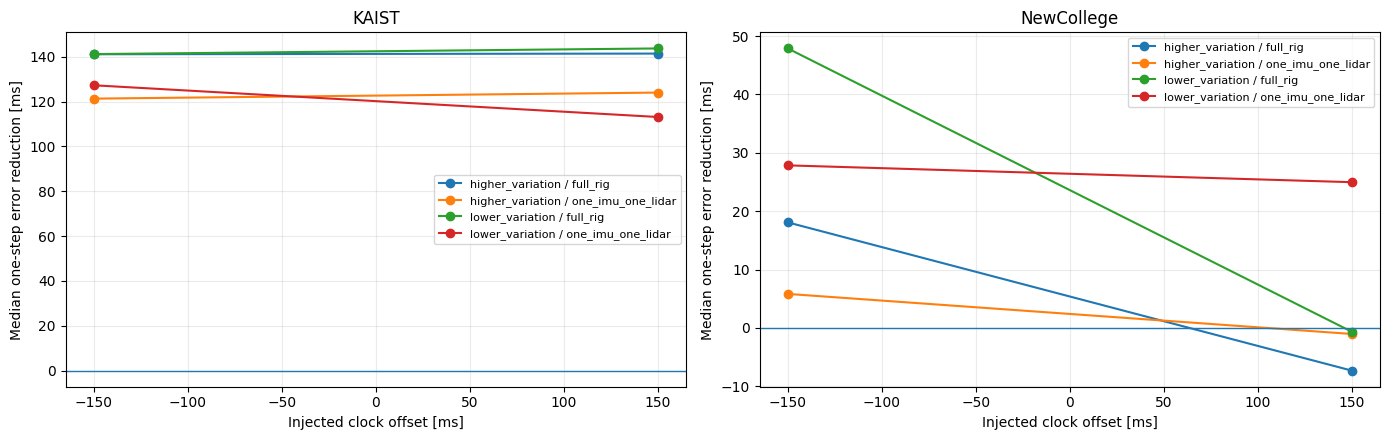

In [61]:
# Insert after notebook37_two_sensor_rotation_ablation.py.
# Time-offset corrections relative to the notebook's nominal references, not absolute clock GT.
assert 'PAIR_CASES' in globals() and 'pair_model_predictions' in globals(), 'Run the one-IMU/one-LiDAR rotation ablation cell first.'

PAIR_TIME_OFFSETS_MS = (-150., 0., 150.)
PAIR_TIME_WINDOWS_PER_SEQUENCE = 2
PAIR_TIME_POOL_CANDIDATES = 24


def clock_perturbed_states(nominal, key, time_delta_ms):
    states = {k: CalibrationState(transform=value.transform.clone(), time_offset=value.time_offset.clone()) for k, value in nominal.items()}
    state = states[key]
    states[key] = CalibrationState(transform=state.transform, time_offset=state.time_offset + time_delta_ms / 1000.)
    return states


def gyro_variation_proxy(window, imu_key):
    # A measure of angular-rate change, useful for stratifying time alignment.
    # This is NOT a numerical Fisher observability score and includes noise.
    gyro_name = next(name for name in window.streams if window.metadata[name].calibration_key == imu_key and 'gyro' in name)
    times = window.streams[gyro_name].timestamps[0].detach().cpu().numpy().astype(float)
    values = window.streams[gyro_name].values[0].detach().cpu().numpy().astype(float)
    dt = np.diff(times)
    valid = dt > 1e-5
    angular_acc = np.linalg.norm(np.diff(values, axis=0)[valid] / dt[valid, None], axis=1)
    return float(np.median(angular_acc)) if len(angular_acc) else np.nan


pair_time_rows = []
with torch.inference_mode():
    for dataset_name, sequence, dataset, available_indices, imu_key, lidar_key in tqdm(PAIR_CASES, desc='Two-sensor clock-offset probe'):
        # Compare less-changing and more-changing motion segments, not just evenly spaced windows.
        candidates = equally_spaced_indices(available_indices, PAIR_TIME_POOL_CANDIDATES)
        ranked = []
        for index in candidates:
            w = get_window(dataset, int(index))
            ranked.append((gyro_variation_proxy(w, imu_key), int(index)))
        ranked = sorted((value, index) for value, index in ranked if np.isfinite(value))
        if not ranked:
            raise RuntimeError(f'No usable gyroscope excitation for {dataset_name}/{sequence}/{imu_key}')
        chosen = [('lower_variation', v, i) for v, i in ranked[:PAIR_TIME_WINDOWS_PER_SEQUENCE]] + [('higher_variation', v, i) for v, i in ranked[-PAIR_TIME_WINDOWS_PER_SEQUENCE:]]
        for motion_bin, excitation, index in chosen:
            full_window = window_batch_to(get_window(dataset, index), DEVICE, dtype=MODEL_DTYPE)
            nominal = full_window.current_calibration
            for selected_key in (imu_key, lidar_key):
                for tau_ms in PAIR_TIME_OFFSETS_MS:
                    full_candidate = clock_perturbed_states(nominal, selected_key, tau_ms)
                    pair_window = subset_sensor_window(full_window, full_candidate, (imu_key, lidar_key))
                    for context_name, window, candidate in (
                        ('full_rig', full_window, full_candidate),
                        ('one_imu_one_lidar', pair_window, pair_window.current_calibration),
                    ):
                        predictions = pair_model_predictions(window, candidate, selected_key)
                        tau_current = float(candidate[selected_key].time_offset.detach().cpu().reshape(-1)[0])
                        tau_nominal = float(nominal[selected_key].time_offset.detach().cpu().reshape(-1)[0])
                        for model_name, prediction in predictions.items():
                            delta_ms = 1000. * prediction['tau_s']
                            after_ms = abs((tau_current + prediction['tau_s'] - tau_nominal) * 1000.)
                            pair_time_rows.append({'dataset': dataset_name, 'sequence': sequence, 'window_index': index, 'imu': imu_key, 'lidar': lidar_key, 'selected_modality': 'imu' if selected_key == imu_key else 'lidar', 'context': context_name, 'model': model_name, 'motion_group': motion_bin, 'gyro_variation_proxy_radps2': excitation, 'injected_tau_ms': tau_ms, 'initial_nominal_tau_error_ms': abs(tau_ms), 'final_nominal_tau_error_ms': after_ms, 'improvement_vs_nominal_ms': abs(tau_ms) - after_ms, 'predicted_tau_update_ms': delta_ms})

pair_time_results = pd.DataFrame(pair_time_rows)
pair_time_results.to_csv(OUT / 'kaist_newcollege_one_imu_one_lidar_clock.csv', index=False)
display(pair_time_results.groupby(['dataset', 'motion_group', 'selected_modality', 'context', 'model', 'injected_tau_ms'])[['improvement_vs_nominal_ms', 'predicted_tau_update_ms', 'gyro_variation_proxy_radps2']].median().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for dataset_name, ax in zip(('KAIST', 'NewCollege'), axes):
    subset = pair_time_results[(pair_time_results.dataset == dataset_name) & (pair_time_results.injected_tau_ms != 0)]
    for (motion_bin, context_name), group in subset.groupby(['motion_group', 'context']):
        values = group.groupby('injected_tau_ms').improvement_vs_nominal_ms.median()
        ax.plot(values.index, values.values, marker='o', label=f'{motion_bin} / {context_name}')
    ax.axhline(0, linewidth=1)
    ax.set(title=dataset_name, xlabel='Injected clock offset [ms]', ylabel='Median one-step error reduction [ms]')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
if SAVE_FIGURES:
    fig.savefig(OUT / 'one_imu_one_lidar_clock_ablation.png', dpi=150)
plt.show()


## 17. Decision-oriented report

Use the following gates in order. **(i)** Timestamp, pose-direction and nominal spatial conventions must be physically plausible. **(ii)** Compare LiDAR rate-normalized roughness *after conditioning on angular speed*, since the motion itself differs. **(iii)** Inspect IMU noise/rate and Transformer-token shift. **(iv)** Compare one-step learned correction direction, before trying extra training augmentations. A scan-to-map versus scan-to-scan causal claim requires a controlled re-registration of the **same scans**, not only these cross-dataset comparisons.

In [58]:
report={'KAIST_sequences':list(KAIST_SEQUENCES),'NewCollege_root':str(NEWCOLLEGE_ROOT),'window_duration_s':WINDOW_DURATION_S,'imu_loaded_rate_hz':TARGET_IMU_FREQUENCY_HZ,'source_claim_KAIST_lidar':'scan-to-map (user-reported)','source_claim_NewCollege_lidar':'scan-to-scan (user-reported)','notes':['Motion distributions and sensor topology differ as well as odometry registration method.','NewCollege absolute IMU/LiDAR tau references are not verified.','Statistical p-values treating windows as independent are exploratory only.','No raw-scan registration fitness, GT odometry error or ground-truth LiDAR trajectory comparison is available here.']}
if len(stat_table):
    report['largest_descriptive_shifts']=stat_table.sort_values('W1_over_pooled_IQR',ascending=False).head(12)[['modality','metric','KAIST_stream','NewCollege_stream','W1_over_pooled_IQR','block_CI_excludes_zero']].to_dict(orient='records')
if not imu_control.empty:
    report['newcollege_imu_imu_optimum_shift_s']=float(imu_control.loc[imu_control.rmse_radps.idxmin(),'shift_s'])
    report['newcollege_imu_imu_min_rmse_radps']=float(imu_control.rmse_radps.min())
if not best_consistency.empty:
    report['best_imu_lidar_alignments']=best_consistency.to_dict(orient='records')
if not probe.empty:
    report['median_one_step_improvement_deg']=probe[probe.perturbation_deg>0].groupby(['dataset','modality','model']).improvement_deg.median().reset_index().to_dict(orient='records')
(OUT/'diagnostic_report.json').write_text(json.dumps(report,indent=2,default=str),encoding='utf-8')
print('Saved:')
for f in sorted(OUT.iterdir()):
    if f.is_file():print(' ',f.name)
print('\nCHECKLIST FOR INTERPRETATION')
print('1. If best LiDAR direction is inverse or tau-sweep optimum sits at the grid boundary, resolve conventions/timing before interpreting NN results.')
print('2. If angular-rate roughness is higher even within motion-matched bins, investigate scan-to-scan edge jitter; NOT yet causal proof.')
print('3. If normalized IMU or token distributions shift, test targeted processing/noise/rate/topology augmentations.')
print('4. If one-step correction directions fail after physical checks pass, prioritize training-domain/topology changes, not rollout gains.')
print('5. To isolate scan-to-map vs scan-to-scan: generate both odometry types from identical scans and rerun the same diagnostics.')

Saved:
  accel_feature_distributions.png
  accel_temporal.png
  correction_probe_transfer.png
  diagnostic_report.json
  distribution_comparisons.csv
  frozen_checkpoint_correction_probe.csv
  gyro_feature_distributions.png
  gyro_temporal.png
  imu_lidar_best_alignment.csv
  imu_lidar_rotation_consistency_sweep.csv
  imu_lidar_time_sweep.png
  lidar_feature_distributions.png
  lidar_roughness_conditioned_on_motion.csv
  lidar_roughness_motion_matched.png
  lidar_temporal.png
  newcollege_gravity_frame_invariance.csv
  newcollege_gravity_frame_invariance.png
  newcollege_imu_to_imu_time_sweep.csv
  newcollege_imu_to_imu_time_sweep.png
  sensor_window_features.csv
  token_std_distribution.png
  token_window_statistics.csv

CHECKLIST FOR INTERPRETATION
1. If best LiDAR direction is inverse or tau-sweep optimum sits at the grid boundary, resolve conventions/timing before interpreting NN results.
2. If angular-rate roughness is higher even within motion-matched bins, investigate scan-to-sc

## Interpretation limitations and proposed follow-up experiment

**What we can establish:** relative distributions of gyroscope/accelerometer measurements, LiDAR motion/roughness proxies, effective frequencies, temporal nonstationarity, IMU–LiDAR rotational consistency and frozen model-input/correction differences.

**What we cannot establish without additional files:** (a) which LiDAR registration algorithm is *causally* responsible; (b) absolute odometry error without an appropriate trajectory truth and aligned conventions; (c) noise levels of each raw scan registration without raw registration fitness/residuals; (d) absolute NewCollege LiDAR-to-IMU time offsets from the Kalibr camera-relative shifts alone.

**Most decisive controlled test:** for NewCollege, compute scan-to-map odometry from exactly the same scans using the KAIST registration pipeline, preserving temporal sampling and calibration. Compare both odometry products against the same native IMUs, in the same window set. Alternatively compute scan-to-scan odometry on KAIST. This isolates registration-type effects far better than more random training augmentations.